# LA LA Stay · Airbnb Los Ángeles
### Análisis de datos y modelos — Equipo Uniandes (Andrés Arismendi y Daniel Babativa)

**Fuente:** Inside Airbnb, `listings.csv.gz` de Los Ángeles (extracción del 14 al 16 de septiembre de 2026), guardado en `data/raw/`.

**Enfoque del proyecto:** estimar y clasificar el **precio por noche** de anuncios con **precio diario** y **activos** de anfitriones con 1–2 anuncios:

| Criterio | Definición |
|---|---|
| Anfitrión pequeño | `calculated_host_listings_count` entre 1 y 2 (usuario del Project Charter) |
| Precio diario | La cotización de Inside Airbnb es de **menos de 28 noches** (con 28 noches o más Airbnb cobra tarifa mensual, sección 3.1) |
| Activo | Tuvo reseñas en los últimos 12 meses **o** ocupación estimada mayor a 0 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', 100)

# Semilla única para todo lo aleatorio del notebook (divisiones, validación cruzada, muestras, red neuronal)
SEED = 42

In [2]:
# Rutas del proyecto: funciona desde cualquier carpeta dentro del repositorio
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / 'data').is_dir():
            return folder
    return start

ROOT = find_project_root()
RAW_FILE = ROOT / 'data' / 'raw' / 'listings.csv.gz'
print('Archivo:', RAW_FILE)

Archivo: /tmp/Proyecto 2/data/raw/listings.csv.gz


### Cargar los datos
`id` y `host_id` se leen como **texto**: los IDs de Inside Airbnb tienen hasta 19 dígitos y, si se leen como número o pasan por Excel, pierden los últimos dígitos.

In [3]:
df = pd.read_csv(RAW_FILE, compression='gzip', low_memory=False,
                 dtype={'id': str, 'host_id': str})

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
df.head()

Filas: 43,781 | Columnas: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2708,https://www.airbnb.com/rooms/2708,20260914002257,2026-09-15,NaN,"Run Runyon, Beaut Furn Mirror Mini-Suit w/ Fir...",Run Runyon Canyon<br /><br />Gym & Sauna <br /...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,3008,https://www.airbnb.com/users/show/3008,1462506333679450606,https://www.airbnb.com/users/profile/146250633...,⁨Chas.⁩,NaN,17,11,15,7,"Los Angeles, CA",Professional and technical writer.\nLiterary C...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/d17cf...,NaN,2,NaN,NaN,t,t,NaN,Hollywood,City of Los Angeles,34.096250,-118.346050,Private room in rental unit,Private room,1,NaN,1 shared bath,1.0,1.0,"[""1801 Beekman Luxury Spa Goat Milk Soap & Han...",$76.31,2027-02-02,2027-03-04,2289.31,76.31,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,NaN,t,6,21,21,246,2026-09-15,47,1,0,21,2,60,4579.0,2014-06-09,2026-05-26,4.87,4.83,4.94,5.00,4.98,4.96,4.87,NaN,NaN,2,0,2,0,0.31
1,2732,https://www.airbnb.com/rooms/2732,20260914002257,2026-09-15,NaN,Zen Life at the Beach,An oasis of tranquility awaits you.,NaN,https://a0.muscache.com/pictures/1082993/c5a99...,3041,https://www.airbnb.com/users/show/3041,1462506335238008418,https://www.airbnb.com/users/profile/146250633...,Yogapriestess,NaN,17,11,15,8,"Santa Monica, CA",I have been teaching yoga and meditation for 3...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/3041/profile_...,NaN,2,NaN,NaN,t,t,NaN,Santa Monica,Other Cities,34.004400,-118.480950,Private room in rental unit,Private room,1,NaN,1 private bath,1.0,1.0,"[""Refrigerator"", ""Private patio or balcony"", ""...",$215.21,2026-09-15,2026-09-22,1506.50,215.21,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",7.0,27.0,7.0,7.0,27.0,27.0,7.0,27.0,NaN,t,30,60,90,365,2026-09-15,24,0,0,108,0,0,0.0,2011-06-06,2022-08-21,4.41,4.26,4.58,4.39,4.48,4.91,4.22,228269,NaN,2,1,1,0,0.13
2,6033,https://www.airbnb.com/rooms/6033,20260914002257,2026-09-14,NaN,Poolside Serenity Studio,Our distinctive bachelor's studio for 1-3 gues...,NaN,https://a0.muscache.com/pictures/458111/986c76...,11619,https://www.airbnb.com/users/show/11619,1462506670443088558,https://www.airbnb.com/users/profile/146250667...,Sarah,NaN,17,5,15,8,"California, United States",My name is Sarah working in property design an...,NaN,NaN,Na

## 1 · Pasar las columnas JSON a columnas
Dos columnas guardan texto en formato JSON: `price_quote_raw` (objeto) y `amenities` (lista). Primero lo confirmamos.

In [4]:
import json

def looks_like_json(series, sample=500):
    values = series.dropna().astype(str).head(sample)
    if values.empty or not values.str.strip().str[:1].isin(['{', '[']).all():
        return False
    try:
        values.map(json.loads)
        return True
    except (ValueError, TypeError):
        return False

json_columns = [col for col in df.select_dtypes('object') if looks_like_json(df[col])]
print('Columnas JSON:', json_columns)
print('Shape inicial:', df.shape)

Columnas JSON: ['amenities', 'price_quote_raw']
Shape inicial: (43781, 90)


### 1.1 · `price_quote_raw`: cada llave es una columna
Cada fila trae `{"quote": {...}}` con 17 llaves. Cada llave pasa a una columna con el prefijo `quote_`.

La llave `raw_price_line_items` es a su vez una **lista** de cobros (hasta 12 por anuncio), y cada cobro tiene 4 llaves: `amount`, `item_type`, `description` y `price_string`. Se expande por posición: `quote_line_item_1_amount`, `quote_line_item_1_item_type`, …, `quote_line_item_12_price_string`. Si un anuncio tiene menos cobros, las columnas sobrantes quedan vacías.

In [5]:
quotes = df['price_quote_raw'].map(lambda raw: json.loads(raw)['quote'] if pd.notna(raw) else {})
quote_df = pd.json_normalize(quotes.tolist()).add_prefix('quote_').set_index(df.index)

# Expandir la lista de cobros por posición
line_items = quote_df.pop('quote_raw_price_line_items')
item_keys = ['amount', 'item_type', 'description', 'price_string']
max_items = int(line_items.map(lambda x: len(x) if isinstance(x, list) else 0).max())

items_df = pd.DataFrame(
    [[(items[i].get(key) if isinstance(items, list) and i < len(items) else None)
      for i in range(max_items) for key in item_keys]
     for items in line_items],
    columns=[f'quote_line_item_{i + 1}_{key}' for i in range(max_items) for key in item_keys],
    index=df.index,
)

print('Llaves de quote:', quote_df.shape[1] + 1, '(incluye raw_price_line_items)')
print('Máximo de cobros por anuncio:', max_items, '->', items_df.shape[1], 'columnas de cobros')

Llaves de quote: 17 (incluye raw_price_line_items)
Máximo de cobros por anuncio: 12 -> 48 columnas de cobros


In [6]:
# Tipos de dato: montos a número, fechas a fecha, banderas a booleano
money = ['quote_taxes', 'quote_total_price', 'quote_discount_amount', 'quote_price_per_night',
         'quote_nightly_subtotal', 'quote_discounted_subtotal']
quote_df[money] = quote_df[money].apply(pd.to_numeric, errors='coerce')
date_cols = [c for c in quote_df.columns if c.endswith('_date')]
quote_df[date_cols] = quote_df[date_cols].apply(pd.to_datetime)
for col in ['quote_is_available', 'quote_is_monthly_priced']:
    quote_df[col] = quote_df[col].astype('boolean')

amount_cols = [c for c in items_df.columns if c.endswith('_amount')]
items_df[amount_cols] = items_df[amount_cols].apply(pd.to_numeric, errors='coerce')

df = pd.concat([df.drop(columns=['price_quote_raw']), quote_df, items_df], axis=1)
print('Shape después de price_quote_raw:', df.shape)

Shape después de price_quote_raw: (43781, 153)


In [7]:
# Llaves que vienen vacías en TODAS las filas (se conservan, pero conviene saberlo)
empty_quote = [c for c in quote_df.columns if quote_df[c].isna().all()]
print('Llaves de quote siempre vacías:', empty_quote)

Llaves de quote siempre vacías: ['quote_date_match', 'quote_service_fee', 'quote_cleaning_fee', 'quote_returned_checkin_date', 'quote_returned_checkout_date']


### 1.2 · `amenities`
`amenities` es una **lista de textos, sin llaves** (por ejemplo `["Wifi", "Kitchen", "Pool"]`). Pasarla a columnas significa crear **una columna por servicio** (1 si el anuncio lo tiene, 0 si no). Aquí solo se calcula cuántas columnas resultarían, sin crearlas todavía.

In [8]:
amenities_list = df['amenities'].map(lambda raw: [a.strip().lower() for a in json.loads(raw)] if pd.notna(raw) else [])
n_amenities = amenities_list.explode().nunique()
print(f'Servicios distintos: {n_amenities:,}')
print(f'Shape si cada servicio fuera una columna: ({df.shape[0]:,}, {df.shape[1] - 1 + n_amenities:,})')

Servicios distintos: 9,820
Shape si cada servicio fuera una columna: (43,781, 9,972)


### 1.3 · ¿Qué valores toma `amenities`?
Tabla de frecuencia de **todos** los servicios: en cuántos anuncios aparece cada uno y qué porcentaje del total representa.

In [9]:
amenity_freq = (amenities_list.explode().dropna()
                .value_counts()
                .rename_axis('amenity')
                .reset_index(name='anuncios'))
amenity_freq['% anuncios'] = (amenity_freq['anuncios'] / len(df) * 100).round(2)

print(f'Servicios distintos: {len(amenity_freq):,}')
print(f'Anuncios sin ningún servicio: {(amenities_list.str.len() == 0).sum()}')
amenity_freq.head(60)

Servicios distintos: 9,820
Anuncios sin ningún servicio: 47


,amenity,anuncios,% anuncios
0,smoke alarm,41723,95.30
1,wifi,40962,93.56
2,carbon monoxide alarm,38438,87.80
3,kitchen,38417,87.75
4,hot water,35177,80.35
5,hangers,33104,75.61
6,hair dryer,31992,73.07
7,essentials,30777,70.30
8,dishes and silverware,30707,70.14
9,microwave,30578,69.84


**Distribución por frecuencia:** cuántos servicios hay en cada rango de popularidad.

In [10]:
n = len(df)
bands = pd.cut(amenity_freq['anuncios'],
               bins=[0, 1, 0.001 * n, 0.01 * n, 0.05 * n, 0.90 * n, n],
               labels=['1 solo anuncio', '2 anuncios a 0,1 %', '0,1 % – 1 %',
                       '1 % – 5 %', '5 % – 90 %', 'más de 90 %'])
band_table = bands.value_counts().sort_index().to_frame('servicios')
band_table['% de servicios'] = (band_table['servicios'] / len(amenity_freq) * 100).round(1)
band_table

,servicios,% de servicios
anuncios,,
1 solo anuncio,6633,67.5
"2 anuncios a 0,1 %",2751,28.0
"0,1 % – 1 %",238,2.4
1 % – 5 %,92,0.9
5 % – 90 %,104,1.1
más de 90 %,2,0.0


**Variantes del mismo servicio:** muchos servicios son el mismo con distinta marca, tamaño o detalle. Ejemplos por palabra clave:

In [11]:
for keyword in ['tv', 'wifi', 'shampoo', 'pool', 'parking', 'coffee']:
    variants = amenity_freq[amenity_freq['amenity'].str.contains(keyword, regex=False)]
    print(f"'{keyword}': {len(variants):,} variantes -> {variants['amenity'].head(6).tolist()}")

print('\nEjemplos de servicios que aparecen en un solo anuncio:')
print(amenity_freq.loc[amenity_freq['anuncios'] == 1, 'amenity'].sample(8, random_state=SEED).tolist())

'tv': 3,150 variantes -> ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv', '65 inch hdtv', 'hdtv with roku']
'wifi': 742 variantes -> ['wifi', 'pocket wifi', 'fast wifi – 229 mbps', 'fast wifi – 364 mbps', 'fast wifi – 224 mbps', 'fast wifi – 87 mbps']
'shampoo': 786 variantes -> ['shampoo', 'pantene shampoo', 'dove shampoo', 'public goods shampoo', 'native shampoo', 'generic shampoo']
'pool': 393 variantes -> ['pool', 'pool table', 'pool view', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
'parking': 73 variantes -> ['free parking on premises', 'free street parking', 'paid parking on premises', 'paid parking off premises', 'free driveway parking on premises – 1 space', 'free parking garage on premises']
'coffee': 62 variantes -> ['coffee maker', 'coffee', 'coffee maker: keurig coffee machine', 'coffee maker: drip coffee maker', 'coffee maker: nespresso', 'coffee maker: drip coffee maker, keurig coffee machine']

Ejemplos de serv

### 1.4 · Unificar las variantes de `amenities`
Cada servicio unificado se define con una **expresión regular** sobre el texto en minúsculas. Un anuncio tiene el servicio si **alguno** de sus textos coincide. Ejemplos:
- `tv` agrupa "tv", "hdtv", "55 inch hdtv with netflix"…
- `pool` agrupa "pool", "private pool", "shared outdoor pool…", pero **no** "pool table" ni "pool view".
- `washer` excluye "dishwasher"; `dryer` excluye "hair dryer".

In [12]:
import re

AMENITY_RULES = {
    # Básicos
    'wifi':              r'\bwi-?fi\b',
    'kitchen':           r'\bkitchen\b',
    'tv':                r'\b(?:hd)?tv\b',
    'workspace':         r'workspace',
    'coffee_maker':      r'coffee maker|espresso|nespresso|keurig',
    # Clima
    'air_conditioning':  r'air conditioning|\bac\b|a/c',
    'heating':           r'heating|\bheater\b',
    'fireplace':         r'fireplace',
    'ceiling_fan':       r'ceiling fan',
    # Lavado y baño
    'washer':            r'(?<!dish)washer',
    'dryer':             r'(?<!hair )\bdryer\b',
    'dishwasher':        r'dishwasher',
    'bathtub':           r'bathtub|soaking tub',
    # Exterior
    'pool':              r'\bpool\b(?! table)(?! view)',
    'hot_tub':           r'hot tub|jacuzzi',
    'patio_balcony':     r'patio|balcony',
    'backyard':          r'backyard',
    'bbq_grill':         r'\bbbq\b|barbecue|\bgrill\b',
    'outdoor_dining':    r'outdoor dining|outdoor furniture',
    'fire_pit':          r'fire pit',
    'garden':            r'\bgarden\b',
    # Acceso y estacionamiento
    'free_parking':      r'free .*parking',
    'paid_parking':      r'paid .*parking',
    'ev_charger':        r'ev charger',
    'private_entrance':  r'private entrance',
    'self_check_in':     r'self check-?in|keypad|lockbox|smart lock',
    'elevator':          r'\belevator\b',
    # Ocio
    'gym':               r'\bgym\b|exercise equipment',
    'sound_system':      r'sound system|bluetooth speaker',
    'game_console':      r'game console|playstation|\bps[45]\b|xbox|nintendo',
    # Ubicación / vistas
    'beach_access':      r'beach access|beachfront',
    'ocean_view':        r'ocean view|sea view|beach view',
    'mountain_view':     r'mountain view',
    'city_view':         r'city skyline view|city view',
    # Familias y políticas
    'crib':              r'\bcrib\b|pack .n play',
    'pets_allowed':      r'pets allowed',
    'long_term_stays':   r'long term stays allowed',
}

joined = amenities_list.map(' | '.join)          # todos los servicios del anuncio en un texto
for name, pattern in AMENITY_RULES.items():
    df[f'am_{name}'] = joined.str.contains(pattern, regex=True).astype(int)
df['amenities_count'] = amenities_list.str.len()

am_cols = [f'am_{name}' for name in AMENITY_RULES]
print(f'{len(am_cols)} servicios unificados creados | Shape: {df.shape}')

37 servicios unificados creados | Shape: (43781, 191)


In [13]:
# Verificación: qué textos originales quedaron dentro de algunos servicios unificados
exploded = amenity_freq.copy()
for name in ['tv', 'pool', 'washer', 'dryer', 'free_parking']:
    hits = exploded[exploded['amenity'].str.contains(AMENITY_RULES[name], regex=True)]
    print(f"{name}: {len(hits):,} variantes, p. ej. {hits['amenity'].head(4).tolist()}")

tv: 3,148 variantes, p. ej. ['tv', 'tv with standard cable', 'hdtv', '55 inch hdtv']
pool: 328 variantes, p. ej. ['pool', 'shared pool', 'private pool', 'shared outdoor pool - available all year, open specific hours']
washer: 10 variantes, p. ej. ['washer', 'free washer – in unit', 'paid washer – in building', 'free washer – in building']
dryer: 10 variantes, p. ej. ['dryer', 'free dryer – in unit', 'free dryer – in building', 'paid dryer – in building']
free_parking: 37 variantes, p. ej. ['free parking on premises', 'free street parking', 'free driveway parking on premises – 1 space', 'free parking garage on premises']


### 1.5 · Frecuencia y relación con el precio
Para comparar precios usamos el **mercado objetivo del Charter**: hosts con 1–2 anuncios, con precio y **sin precio mensual** (`quote_is_monthly_priced = False`).
Se compara el **precio mediano** de los anuncios con y sin cada servicio. Es una comparación **descriptiva, no causal**: un servicio puede ir junto con propiedades más grandes o mejor ubicadas.

In [14]:
df['price_num'] = pd.to_numeric(df['price'].str.replace(r'[\$,]', '', regex=True), errors='coerce')
target = df[df['calculated_host_listings_count'].between(1, 2)
            & df['price_num'].notna()
            & (df['quote_is_monthly_priced'] == False)]
print(f'Anuncios del mercado objetivo: {len(target):,}')

rows = []
for col in am_cols:
    has = target[col] == 1
    rows.append({
        'servicio': col.removeprefix('am_'),
        '% anuncios (todos)': df[col].mean() * 100,
        '% mercado objetivo': has.mean() * 100,
        'mediana con': target.loc[has, 'price_num'].median(),
        'mediana sin': target.loc[~has, 'price_num'].median(),
    })
amenity_summary = pd.DataFrame(rows)
amenity_summary['diferencia %'] = (amenity_summary['mediana con'] / amenity_summary['mediana sin'] - 1) * 100
amenity_summary['entre 5 % y 90 %'] = amenity_summary['% mercado objetivo'].between(5, 90)
amenity_summary = amenity_summary.sort_values('% mercado objetivo', ascending=False).round(1).reset_index(drop=True)
amenity_summary

Anuncios del mercado objetivo: 8,782


,servicio,% anuncios (todos),% mercado objetivo,mediana con,mediana sin,diferencia %,entre 5 % y 90 %
0,wifi,98.6,98.9,283.5,221.5,28.0,False
1,tv,89.5,92.2,293.5,160.0,83.4,False
2,free_parking,83.4,91.6,287.5,238.5,20.5,False
3,air_conditioning,89.1,89.6,285.0,258.0,10.5,True
4,heating,84.6,87.5,289.2,220.5,31.2,True
5,kitchen,87.9,85.1,309.8,174.0,78.0,True
6,coffee_maker,68.1,78.3,298.6,209.0,42.9,True
7,washer,79.5,72.6,326.0,205.8,58.4,True
8,self_check_in,57.6,66.7,295.0,250.0,18.0,True
9,dryer,69.2,65.4,332.0,211.3,57.1,True


### 1.6 · Servicios seleccionados
Se descartan 9 servicios unificados:
- **Casi universales (más del 90 % del mercado objetivo):** `wifi`, `tv`, `free_parking`. No diferencian un anuncio de otro.
- **Muy raros (menos del 5 %):** `ocean_view`, `game_console`.
- **Diferencia de precio pequeña o ambigua:** `ceiling_fan`, `elevator`, `private_entrance` (5 %–8 %) y `paid_parking` (negativa: suele indicar zonas densas, no un servicio que agregue valor).

Se conservan los demás servicios más `amenities_count`, y se elimina la columna JSON original `amenities`.

In [15]:
DROP_AMENITIES = ['wifi', 'tv', 'free_parking', 'ocean_view', 'game_console',
                  'ceiling_fan', 'elevator', 'private_entrance', 'paid_parking']

df = df.drop(columns=[f'am_{name}' for name in DROP_AMENITIES] + ['amenities'])
am_cols = [col for col in df.columns if col.startswith('am_')]

print(f'Servicios conservados ({len(am_cols)}):')
print([col.removeprefix('am_') for col in am_cols])
print(f'\nShape: {df.shape}')

Servicios conservados (28):
['kitchen', 'workspace', 'coffee_maker', 'air_conditioning', 'heating', 'fireplace', 'washer', 'dryer', 'dishwasher', 'bathtub', 'pool', 'hot_tub', 'patio_balcony', 'backyard', 'bbq_grill', 'outdoor_dining', 'fire_pit', 'garden', 'ev_charger', 'self_check_in', 'gym', 'sound_system', 'beach_access', 'mountain_view', 'city_view', 'crib', 'pets_allowed', 'long_term_stays']

Shape: (43781, 182)


## 2 · Selección de columnas
### 2.1 · Variables derivadas antes de eliminar
Antes de quitar las columnas de la cotización se calculan dos variables útiles:
- `quote_nights`: noches que se cotizaron (de 1 a 365, según las noches mínimas).
- `base_nightly_rate`: **tarifa publicada por noche sin descuentos** = `quote_nightly_subtotal / quote_nights`. Existe solo para los anuncios con precio diario (no mensuales). Es una posible variable objetivo alternativa a `price`, que ya trae descuentos aplicados.

In [16]:
df['quote_nights'] = (df['quote_requested_checkout_date'] - df['quote_requested_checkin_date']).dt.days
# Solo tiene sentido con precio diario: en las cotizaciones mensuales no hay tarifa por noche
df['base_nightly_rate'] = (df['quote_nightly_subtotal'] / df['quote_nights']).where(df['quote_is_monthly_priced'] == False)

print(f"Anuncios con tarifa base: {df['base_nightly_rate'].notna().sum():,}")
print(pd.crosstab(df['base_nightly_rate'].notna(), df['quote_is_monthly_priced'],
                  rownames=['tiene tarifa base'], colnames=['precio mensual']))

Anuncios con tarifa base: 19,986
precio mensual     False  True 
tiene tarifa base              
False                753  18004
True               19986      0


### 2.2 · Columnas a eliminar, por grupo
Cada grupo indica **por qué** se elimina. Al final se verifica que ninguna columna quede sin clasificar.

In [17]:
always_empty = [col for col in df.columns if df[col].isna().all()]

DROP_GROUPS = {
    'Vacías en todas las filas': always_empty,
    'Metadatos de la extracción': [
        'scrape_id', 'last_scraped', 'calendar_last_scraped', 'source', 'quote_currency',
        'quote_requested_checkin_date', 'quote_requested_checkout_date'],
    'URLs, identificadores secundarios y texto libre': [
        'listing_url', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url',
        'host_picture_url', 'host_name', 'name', 'description', 'host_about', 'host_location', 'license'],
    'Derivadas del precio (fuga hacia la variable objetivo)': [
        'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price',
        'price_quote_price_per_night', 'estimated_revenue_l365d', 'quote_total_price',
        'quote_price_per_night', 'quote_taxes', 'quote_discount_amount', 'quote_nightly_subtotal',
        'quote_discounted_subtotal'] + [c for c in df.columns if c.startswith('quote_line_item_')],
    'Redundantes': [
        'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights',
        'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm',
        'host_listings_count', 'calculated_host_listings_count_entire_homes',
        'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms',
        'hosts_time_as_user_years', 'hosts_time_as_user_months'],
    'Desempeño del anuncio (un anfitrión nuevo no lo conoce)': [
        'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
        'review_scores_checkin', 'review_scores_communication', 'review_scores_location',
        'review_scores_value', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'reviews_per_month',
        'first_review', 'availability_30', 'availability_60', 'availability_90', 'availability_eoy',
        'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified',
        'hosts_time_as_host_years', 'hosts_time_as_host_months', 'quote_is_available'],
}

# Una columna puede estar en "vacías" y en otro grupo; se cuenta una sola vez
to_drop = list(dict.fromkeys(col for cols in DROP_GROUPS.values() for col in cols))
missing = [col for col in to_drop if col not in df.columns]
assert not missing, f'Columnas inexistentes: {missing}'

summary = pd.DataFrame({'grupo': list(DROP_GROUPS),
                        'columnas': [len(cols) for cols in DROP_GROUPS.values()]})
display(summary)
print(f'Total a eliminar (sin repetir): {len(to_drop)}')

,grupo,columnas
0,Vacías en todas las filas,18
1,Metadatos de la extracción,7
2,"URLs, identificadores secundarios y texto libre",13
3,Derivadas del precio (fuga hacia la variable o...,60
4,Redundantes,12
5,Desempeño del anuncio (un anfitrión nuevo no l...,21


Total a eliminar (sin repetir): 131


In [18]:
df = df.drop(columns=to_drop)
print(f'Shape: {df.shape}')

Shape: (43781, 53)


### 2.3 · Columnas conservadas

In [19]:
KEEP_GROUPS = {
    'Clave': ['id'],
    'Variables objetivo (candidatas)': ['price_num', 'base_nightly_rate'],
    'Características de la propiedad': [
        'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude',
        'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'bathrooms_text'],
    'Servicios': [c for c in df.columns if c.startswith('am_')] + ['amenities_count'],
    'Filtros del mercado objetivo': [
        'calculated_host_listings_count', 'minimum_nights', 'maximum_nights',
        'quote_is_monthly_priced', 'quote_nights'],
    'Actividad (solo análisis, no van al modelo)': [
        'number_of_reviews', 'number_of_reviews_ltm', 'last_review', 'availability_365',
        'estimated_occupancy_l365d', 'has_availability'],
}
classified = [col for cols in KEEP_GROUPS.values() for col in cols]
unclassified = sorted(set(df.columns) - set(classified))
assert not unclassified, f'Columnas sin clasificar: {unclassified}'

df = df[classified]
df['last_review'] = pd.to_datetime(df['last_review'])
df['has_availability'] = df['has_availability'].map({'t': True, 'f': False}).astype('boolean')

display(pd.DataFrame({'grupo': list(KEEP_GROUPS), 'columnas': [len(c) for c in KEEP_GROUPS.values()]}))
print(f'Shape final: {df.shape}')

,grupo,columnas
0,Clave,1
1,Variables objetivo (candidatas),2
2,Características de la propiedad,10
3,Servicios,29
4,Filtros del mercado objetivo,5
5,"Actividad (solo análisis, no van al modelo)",6


Shape final: (43781, 53)


## 3 · Limpieza
Igual que el equipo del TEC, **no se borran filas**: los casos problemáticos se **marcan** con columnas 0/1 y se excluyen solo al entrenar.

Los pasos 3.2 y 3.4 reutilizan la lógica del notebook de limpieza del TEC (`Data_LA_Clean.ipynb`, Lorena Martínez). Para que los resultados sean comparables con los suyos, las medianas y los conteos de esos pasos se calculan sobre la misma población: **hosts con 1–2 anuncios**.

### 3.1 · Marcas del mercado objetivo
| Marca | Definición |
|---|---|
| `is_small_host` | El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter). |
| `has_price` | El anuncio tiene precio. |
| `is_monthly` | La cotización es de **28 noches o más** (`quote_nights ≥ 28`): Airbnb la cobra como estadía mensual. |
| `is_inactive` | Sin reseñas en los últimos 12 meses **y** ocupación estimada de 0 días. |
| `in_target_market` | `is_small_host` **y** `has_price` **y no** `is_monthly` **y no** `is_inactive`. |
| `is_hotel` | `room_type` es *Hotel room*: no corresponde a un anfitrión independiente. |
| `price_outlier` | Precio menor a USD 20 o mayor al percentil 99 **del mercado objetivo**. |

In [20]:
df['is_small_host'] = df['calculated_host_listings_count'].between(1, 2).astype(int)
df['has_price'] = df['price_num'].notna().astype(int)
df['is_monthly'] = (df['quote_nights'] >= 28).astype(int)
df['is_inactive'] = ((df['number_of_reviews_ltm'] == 0)
                     & (df['estimated_occupancy_l365d'] == 0)).astype(int)
df['in_target_market'] = ((df['is_small_host'] == 1) & (df['has_price'] == 1)
                          & (df['is_monthly'] == 0) & (df['is_inactive'] == 0)).astype(int)
df['is_hotel'] = (df['room_type'] == 'Hotel room').astype(int)

PRICE_MIN = 20
PRICE_MAX = df.loc[df['in_target_market'] == 1, 'price_num'].quantile(0.99)
df['price_outlier'] = (df['has_price'].astype(bool)
                       & ((df['price_num'] < PRICE_MIN) | (df['price_num'] > PRICE_MAX))).astype(int)
print(f'Rango de precio aceptado: USD {PRICE_MIN} – {PRICE_MAX:,.2f} (percentil 99 del mercado objetivo)')

flags = ['is_small_host', 'has_price', 'is_monthly', 'is_inactive', 'in_target_market', 'is_hotel', 'price_outlier']
target = df['in_target_market'] == 1
pd.DataFrame({'todos los anuncios': df[flags].sum(),
              'dentro del mercado objetivo': df.loc[target, flags].sum()})

Rango de precio aceptado: USD 20 – 1,747.78 (percentil 99 del mercado objetivo)


,todos los anuncios,dentro del mercado objetivo
is_small_host,20541,7404
has_price,36687,7404
is_monthly,18512,0
is_inactive,19290,0
in_target_market,7404,7404
is_hotel,412,1
price_outlier,790,76


**¿Por qué el corte es 28 noches?** Inside Airbnb pide a Airbnb una cotización para una estadía de tantas noches como las **noches mínimas** del anuncio, y el `price` es *total cotizado ÷ noches*. La tabla cruza las noches cotizadas con la marca `quote_is_monthly_priced` que devuelve Airbnb: **ninguna** cotización de menos de 28 noches es mensual y casi todas las de 28 o más sí lo son. Las pocas de 28+ noches sin la marca son cotizaciones vacías (sin precio) o se calcularon como tarifa diaria × noches con descuento mensual; igual son estadías mensuales, por eso se usa el número de noches y no la marca.

El filtro del TEC (`long_stay` = noches mínimas **> 30**) deja pasar los anuncios con 28–30 noches mínimas, que son la mayoría de los mensuales.

In [21]:
night_bins = pd.cut(df['quote_nights'], [0, 7, 14, 27, 28, 30, 31, np.inf],
                    labels=['1–7', '8–14', '15–27', '28', '29–30', '31', '32 o más'])
monthly_check = df.groupby(night_bins, observed=True).agg(
    cotizaciones=('quote_nights', 'size'),
    pct_marcadas_mensual=('quote_is_monthly_priced', lambda s: (s == True).mean() * 100),
    con_precio=('has_price', 'sum'))
display(monthly_check.round(1).rename_axis('noches cotizadas'))
print(f"Coinciden noches cotizadas y noches mínimas: {(df['quote_nights'] == df['minimum_nights']).mean():.1%} de los anuncios")

,cotizaciones,pct_marcadas_mensual,con_precio
noches cotizadas,,,
1–7,19654,0.0,19405
8–14,358,0.0,353
15–27,219,0.0,212
28,259,98.5,240
29–30,13981,98.0,12769
31,3807,94.6,3296
32 o más,465,96.3,412


Coinciden noches cotizadas y noches mínimas: 82.8% de los anuncios


### 3.2 · Habitaciones y camas vacías
Lógica del TEC: se rellenan con la **mediana de anuncios similares** (mismo `room_type` y misma capacidad `accommodates`). Si ese grupo tiene menos de 10 anuncios, se usa la mediana del `room_type`. Se guarda el valor original y una marca de imputación. Se aplica igual a `beds`, que el TEC no usaba.

In [22]:
small = df['is_small_host'] == 1

def impute_by_similar(column, min_group=10):
    group = ['room_type', 'accommodates']
    stats = df[small].groupby(group)[column].agg(['median', 'count']).reset_index()
    room_median = df[small].groupby('room_type')[column].median()
    stats.loc[stats['count'] < min_group, 'median'] = stats['room_type'].map(room_median)

    fill = df[group].merge(stats[group + ['median']], on=group, how='left')['median'].to_numpy()
    fill = np.where(np.isnan(fill), df['room_type'].map(room_median), fill)   # combinaciones no vistas

    df[f'{column}_original'] = df[column]
    df[f'{column}_imputed'] = df[column].isna().astype(int)
    df[column] = df[column].fillna(pd.Series(fill, index=df.index))

for column in ['bedrooms', 'beds']:
    impute_by_similar(column)
    print(f"{column}: {df[f'{column}_imputed'].sum():,} valores rellenados "
          f"({df.loc[small, f'{column}_imputed'].sum():,} en hosts 1–2)")

bedrooms: 90 valores rellenados (58 en hosts 1–2)


beds: 1,077 valores rellenados (362 en hosts 1–2)


### 3.3 · Baños: de texto a número
`bathrooms_text` mezcla número y tipo (*"1.5 shared baths"*, *"Private half-bath"*). Se separa en:
- `bathrooms`: número de baños; *half-bath* = 0,5.
- `bathroom_shared`: 1 si el baño es compartido.

Los 74 vacíos se rellenan con la misma lógica de 3.2.

In [23]:
text = df['bathrooms_text'].str.lower()
df['bathrooms'] = pd.to_numeric(text.str.extract(r'^(\d+(?:\.\d+)?)')[0], errors='coerce')
df.loc[text.str.contains('half-bath', na=False), 'bathrooms'] = 0.5
df['bathroom_shared'] = text.str.contains('shared', na=False).astype(int)

impute_by_similar('bathrooms')
df = df.drop(columns=['bathrooms_original'])           # el original queda en bathrooms_text

print(f"Baños rellenados: {df['bathrooms_imputed'].sum()}")
print(df[['bathrooms_text', 'bathrooms', 'bathroom_shared']].drop_duplicates()
        .sort_values('bathrooms').head(12).to_string(index=False))

Baños rellenados: 74
   bathrooms_text  bathrooms  bathroom_shared
          0 baths        0.0                0
   0 shared baths        0.0                1
 Shared half-bath        0.5                1
        Half-bath        0.5                0
Private half-bath        0.5                0
           1 bath        1.0                0
    1 shared bath        1.0                1
   1 private bath        1.0                0
              NaN        1.0                0
 1.5 shared baths        1.5                1
        1.5 baths        1.5                0
          2 baths        2.0                0


### 3.4 · Tipos de propiedad raros y vecindarios pequeños
**Tipos de propiedad** (lógica del TEC): los tipos con menos de 100 anuncios se agrupan según `room_type`. Corrección respecto al TEC: allí los hoteles raros quedaban dentro de *Shared room*; aquí van en su propio grupo, *Unique hotel room*.

**Vecindarios** (lógica del TEC, calculada con código): los vecindarios con menos de 10 anuncios se unen al **vecindario más cercano** con 10 o más, medido como distancia entre centros (mediana de latitud y longitud de sus anuncios). El TEC escribió el mapa de uniones a mano; aquí se calcula, para que sea reproducible.

In [24]:
# Tipos de propiedad
type_counts = df.loc[small, 'property_type'].value_counts()
rare = df['property_type'].map(type_counts).fillna(0) < 100
rare_label = df['room_type'].map({'Entire home/apt': 'Unique entire place',
                                  'Private room': 'Unique private room',
                                  'Shared room': 'Shared room',
                                  'Hotel room': 'Unique hotel room'})
df['property_type_model'] = np.where(rare, rare_label, df['property_type'])
print(f"Tipos de propiedad (hosts 1–2): {df.loc[small, 'property_type'].nunique()} -> "
      f"{df.loc[small, 'property_type_model'].nunique()}")

Tipos de propiedad (hosts 1–2): 80 -> 22


In [25]:
# Vecindarios
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

hood_counts = df.loc[small, 'neighbourhood_cleansed'].value_counts()
centers = df[small].groupby('neighbourhood_cleansed')[['latitude', 'longitude']].median()
large = hood_counts[hood_counts >= 10].index

neighbourhood_map = {}
for hood in df['neighbourhood_cleansed'].unique():
    if hood_counts.get(hood, 0) >= 10:
        continue
    lat, lon = (centers.loc[hood] if hood in centers.index
                else df.loc[df['neighbourhood_cleansed'] == hood, ['latitude', 'longitude']].median())
    distances = haversine_km(lat, lon, centers.loc[large, 'latitude'], centers.loc[large, 'longitude'])
    neighbourhood_map[hood] = distances.idxmin()

df['neighbourhood_model'] = df['neighbourhood_cleansed'].replace(neighbourhood_map)
print(f"Vecindarios (hosts 1–2): {df.loc[small, 'neighbourhood_cleansed'].nunique()} -> "
      f"{df.loc[small, 'neighbourhood_model'].nunique()}")
print(f'Vecindarios unidos a otro: {len(neighbourhood_map)}')
pd.Series(neighbourhood_map, name='unido a').rename_axis('vecindario').head(10)

Vecindarios (hosts 1–2): 263 -> 212
Vecindarios unidos a otro: 52


vecindario
North Whittier    West Whittier-Los Nietos
Val Verde                          Castaic
Vincent                              Azusa
Arleta                       Panorama City
Citrus                               Azusa
Elysian Park                     Chinatown
Irwindale                           Duarte
Green Meadows          Broadway-Manchester
Ridge Route                        Castaic
Rolling Hills        Rolling Hills Estates
Name: unido a, dtype: object

### 3.5 · Validaciones automáticas
Si alguna condición falla, el notebook se detiene con un mensaje. Las inconsistencias que no se pueden corregir con certeza se **marcan** en vez de detener el proceso.

**Corrección previa:** Airbnb permite como máximo 1.125 noches. Valores mayores en `maximum_nights` (por ejemplo 2.147.483.647, el máximo de un entero de 32 bits) son marcadores de "sin límite", no estancias reales: se recortan a 1.125 y se marcan con `maximum_nights_capped`.


In [26]:
# Corrección: noches máximas por encima del límite de Airbnb (1.125) son marcadores de "sin límite"
MAX_NIGHTS_AIRBNB = 1125
df['maximum_nights_capped'] = (df['maximum_nights'] > MAX_NIGHTS_AIRBNB).astype(int)
print(f"Noches máximas recortadas a {MAX_NIGHTS_AIRBNB}: {df['maximum_nights_capped'].sum()} anuncios "
      f"(valor máximo original: {df['maximum_nights'].max():,.0f})")
df['maximum_nights'] = df['maximum_nights'].clip(upper=MAX_NIGHTS_AIRBNB)

# Estructura
assert len(df) == 43_781, 'Cambió el número de filas'
assert df['id'].is_unique, 'Hay IDs repetidos'
assert df['id'].str.fullmatch(r'\d+').all(), 'Hay IDs que no son solo dígitos'
assert df['is_small_host'].sum() == 20_541, 'El filtro de hosts no coincide con el del TEC (20.541)'

# Rangos válidos
assert df['latitude'].between(33.2, 34.9).all() and df['longitude'].between(-119.0, -117.6).all(), \
    'Hay coordenadas fuera del condado de Los Ángeles'
assert (df['accommodates'] >= 1).all(), 'Hay anuncios con capacidad menor a 1'
assert (df['maximum_nights'].dropna() <= MAX_NIGHTS_AIRBNB).all(), 'Hay noches máximas por encima del límite de Airbnb'
assert (df.loc[df['has_price'] == 1, 'price_num'] > 0).all(), 'Hay precios no positivos'
assert (df['bathrooms'] >= 0).all() and (df['bedrooms'] >= 0).all(), 'Hay baños o habitaciones negativos'

# Sin vacíos en las variables del modelo
model_cols = ['bedrooms', 'beds', 'bathrooms', 'accommodates', 'neighbourhood_model',
              'property_type_model', 'room_type', 'amenities_count']
nulls = df[model_cols].isna().sum()
assert nulls.sum() == 0, f'Quedan vacíos en variables del modelo: {nulls[nulls > 0].to_dict()}'

# Inconsistencia que se marca: más habitaciones que huéspedes (no se sabe cuál de los dos valores está mal)
df['bedrooms_gt_guests'] = (df['bedrooms'] > df['accommodates']).astype(int)
print('Todas las validaciones pasaron.')
print(f"Anuncios con más habitaciones que huéspedes: {df['bedrooms_gt_guests'].sum()} "
      f"({df.loc[small, 'bedrooms_gt_guests'].sum()} en hosts 1–2)")
print(f'Shape: {df.shape}')

Noches máximas recortadas a 1125: 18 anuncios (valor máximo original: 2,147,483,647)


Todas las validaciones pasaron.
Anuncios con más habitaciones que huéspedes: 203 (118 en hosts 1–2)
Shape: (43781, 71)


### 3.6 · DataFrame limpio: anuncios diarios y activos
Hasta aquí la limpieza solo **marcó** problemas. Ahora se crea **`df_limpio`**, quitando las filas que quedan fuera del enfoque:

| Se queda si… | Marca |
|---|---|
| El anfitrión tiene 1 o 2 anuncios (usuario del Project Charter) | `is_small_host = 1` |
| Tiene precio | `has_price = 1` |
| No es un hotel | `is_hotel = 0` |
| No tiene precio extremo | `price_outlier = 0` |
| Tiene precio **diario** (cotización de menos de 28 noches) | `is_monthly = 0` |
| Está **activo** | `is_inactive = 0` |

`df` completo se conserva sin cambios.

In [27]:
base = (df['is_small_host'] == 1) & (df['has_price'] == 1)
steps = [
    ('Todos los anuncios', pd.Series(True, index=df.index)),
    ('Hosts con 1–2 anuncios', df['is_small_host'] == 1),
    ('Con precio', base),
    ('Sin hoteles', base & (df['is_hotel'] == 0)),
    ('Sin precios extremos', base & (df['is_hotel'] == 0) & (df['price_outlier'] == 0)),
    ('Solo precio diario (< 28 noches)', base & (df['is_hotel'] == 0) & (df['price_outlier'] == 0) & (df['is_monthly'] == 0)),
    ('Solo activos', base & (df['is_hotel'] == 0) & (df['price_outlier'] == 0) & (df['is_monthly'] == 0)
                     & (df['is_inactive'] == 0)),
]
funnel = pd.DataFrame([(name, int(mask.sum())) for name, mask in steps], columns=['paso', 'anuncios'])
funnel['excluidos en el paso'] = (-funnel['anuncios'].diff()).fillna(0).astype(int)

df_limpio = df[steps[-1][1]].copy()
df['in_training'] = df['id'].isin(df_limpio['id']).astype(int)
print(f'df_limpio: {df_limpio.shape}')
funnel

df_limpio: (7327, 71)


,paso,anuncios,excluidos en el paso
0,Todos los anuncios,43781,0
1,Hosts con 1–2 anuncios,20541,23240
2,Con precio,16304,4237
3,Sin hoteles,16301,3
4,Sin precios extremos,16050,251
5,Solo precio diario (< 28 noches),8611,7439
6,Solo activos,7327,1284


### 3.7 · ¿Por qué solo anuncios diarios y activos?
Comparación de los anuncios que quedan fuera en los dos últimos pasos (hosts 1–2, con precio, sin hoteles ni precios extremos):
- **Mensuales:** su `price` es una tarifa mensual con descuento repartida en 28 o más noches; es otro producto, con un precio por noche mucho más bajo.
- **Inactivos:** no tuvieron reseñas ni ocupación en un año, así que su precio no ha sido validado por ninguna reserva.

In [28]:
before_filters = df[steps[4][1]]
segment = np.select([before_filters['is_monthly'] == 1, before_filters['is_inactive'] == 1],
                    ['Mensual (fuera)', 'Diario inactivo (fuera)'], default='Diario activo (df_limpio)')
segment_table = before_filters.groupby(segment).agg(
    anuncios=('price_num', 'size'),
    precio_mediano=('price_num', 'median'),
    ocupacion_mediana_dias=('estimated_occupancy_l365d', 'median'),
    resenas_12m_medianas=('number_of_reviews_ltm', 'median'))
segment_table.reindex(['Diario activo (df_limpio)', 'Diario inactivo (fuera)', 'Mensual (fuera)']).round(1)

,anuncios,precio_mediano,ocupacion_mediana_dias,resenas_12m_medianas
Diario activo (df_limpio),7327,280.0,120.0,19.0
Diario inactivo (fuera),1284,261.7,0.0,0.0
Mensual (fuera),7439,147.1,0.0,0.0


### 3.8 · Quitar columnas repetidas o constantes
En `df_limpio` se eliminan:
- **Repetida:** `quote_is_monthly_priced` (se reemplazó por `is_monthly`).
- **Constantes por el filtro:** las marcas que se usaron para crear `df_limpio` valen lo mismo en todas las filas (`is_small_host`, `has_price`, `is_hotel`, `price_outlier`, `is_monthly`, `is_inactive`, `in_target_market`).

Al final se verifica que no quede ninguna columna constante.

In [29]:
REDUNDANT = ['quote_is_monthly_priced']
FILTER_FLAGS = ['is_small_host', 'has_price', 'is_hotel', 'price_outlier', 'is_monthly', 'is_inactive', 'in_target_market']

constant = [c for c in FILTER_FLAGS if df_limpio[c].nunique(dropna=False) == 1]
assert constant == FILTER_FLAGS, f'Estas marcas no son constantes: {set(FILTER_FLAGS) - set(constant)}'
df_limpio = df_limpio.drop(columns=REDUNDANT + FILTER_FLAGS)

still_constant = [c for c in df_limpio.columns if df_limpio[c].nunique(dropna=False) <= 1]
if still_constant:
    print(f'Columnas constantes adicionales que se quitan: {still_constant}')
    df_limpio = df_limpio.drop(columns=still_constant)
print(f'df_limpio: {df_limpio.shape}')

df_limpio: (7327, 63)


## 4 · Análisis de variables y del precio
Esta sección reorganiza el análisis de Daniel Babativa en este orden:

1. **Correlación** de cada variable con el **precio original** (`price_num`).
2. **Limpieza de variables:** de cada pareja muy correlacionada se deja solo la que mejor explica el precio.
3. **ANOVA de cada variable:** se quitan las que no explican el precio de forma significativa.
4. **Distribución** del precio (original vs. logaritmo), con gráficas y pruebas estadísticas.
5. **DataFrame final** para el modelo.

Se trabaja sobre `df_limpio` (anuncios diarios y activos de hosts con 1–2 anuncios, sin hoteles ni precios extremos).

### 4.1 · Correlación de cada variable con el precio original
**Variables candidatas a predictor.** Antes de medir correlaciones se dejan fuera, por definición, las columnas que no pueden ser predictores:

| Columna | Por qué no es predictor |
|---|---|
| `id` | Identificador, no describe la propiedad. |
| `base_nightly_rate` | Es otra medida del precio (variable objetivo alternativa): usarla filtraría la respuesta. |
| Actividad: `number_of_reviews`, `number_of_reviews_ltm`, `last_review`, `availability_365`, `estimated_occupancy_l365d`, `has_availability` | Resultados de operar el anuncio; un anfitrión nuevo no los conoce. |
| `bedrooms_original`, `beds_original`, `*_imputed`, `bedrooms_gt_guests` | Control de calidad de la limpieza. |
| `bathrooms_text` | Texto: ya está convertido en `bathrooms` y `bathroom_shared`. |
| `neighbourhood_cleansed`, `property_type` | Versiones sin agrupar: se usan `neighbourhood_model` y `property_type_model`. |
| `calculated_host_listings_count`, marcas de limpieza, `activo` | Filtros de la población, no características de la propiedad. |

**Medidas de correlación:**
- Variables numéricas y servicios (0/1): **Pearson** y **Spearman**. Como el precio es muy asimétrico (sección 4.4), el criterio para decidir es **Spearman**, que usa rangos y no se deja arrastrar por los precios extremos.
- Variables categóricas: **razón de correlación η (eta)**, que mide qué parte de la variación del precio explican las categorías (η² = proporción explicada).

In [30]:
from scipy import stats

am_cols = [c for c in df_limpio.columns if c.startswith('am_')]
NUMERIC_CANDIDATES = ['accommodates', 'bedrooms', 'beds', 'bathrooms', 'bathroom_shared', 'amenities_count',
                      'minimum_nights', 'maximum_nights', 'quote_nights', 'latitude', 'longitude'] + am_cols
CATEGORICAL_CANDIDATES = ['neighbourhood_model', 'neighbourhood_group_cleansed', 'property_type_model', 'room_type']

price = df_limpio['price_num']

def correlation_ratio(categories, values):
    # η: raíz de la proporción de la varianza de `values` explicada por las categorías
    groups = values.groupby(categories)
    between = (groups.count() * (groups.mean() - values.mean()) ** 2).sum()
    total = ((values - values.mean()) ** 2).sum()
    return np.sqrt(between / total)

corr_table = pd.DataFrame({
    'tipo': 'numérica',
    'Pearson': df_limpio[NUMERIC_CANDIDATES].corrwith(price),
    'Spearman': df_limpio[NUMERIC_CANDIDATES].corrwith(price, method='spearman'),
})
cat_table = pd.DataFrame({
    'tipo': 'categórica',
    'eta (η)': [correlation_ratio(df_limpio[c], price) for c in CATEGORICAL_CANDIDATES],
}, index=CATEGORICAL_CANDIDATES)
corr_table = pd.concat([corr_table, cat_table])
corr_table['fuerza (|Spearman| o η)'] = corr_table['Spearman'].abs().fillna(corr_table['eta (η)'])
corr_table = corr_table.sort_values('fuerza (|Spearman| o η)', ascending=False)
corr_table.round(3)

,tipo,Pearson,Spearman,eta (η),fuerza (|Spearman| o η)
accommodates,numérica,0.614,0.695,NaN,0.695
bedrooms,numérica,0.648,0.682,NaN,0.682
bathrooms,numérica,0.678,0.651,NaN,0.651
beds,numérica,0.547,0.638,NaN,0.638
property_type_model,categórica,NaN,NaN,0.564,0.564
neighbourhood_model,categórica,NaN,NaN,0.501,0.501
am_dishwasher,numérica,0.417,0.487,NaN,0.487
amenities_count,numérica,0.353,0.417,NaN,0.417
am_dryer,numérica,0.288,0.340,NaN,0.340
am_kitchen,numérica,0.258,0.338,NaN,0.338


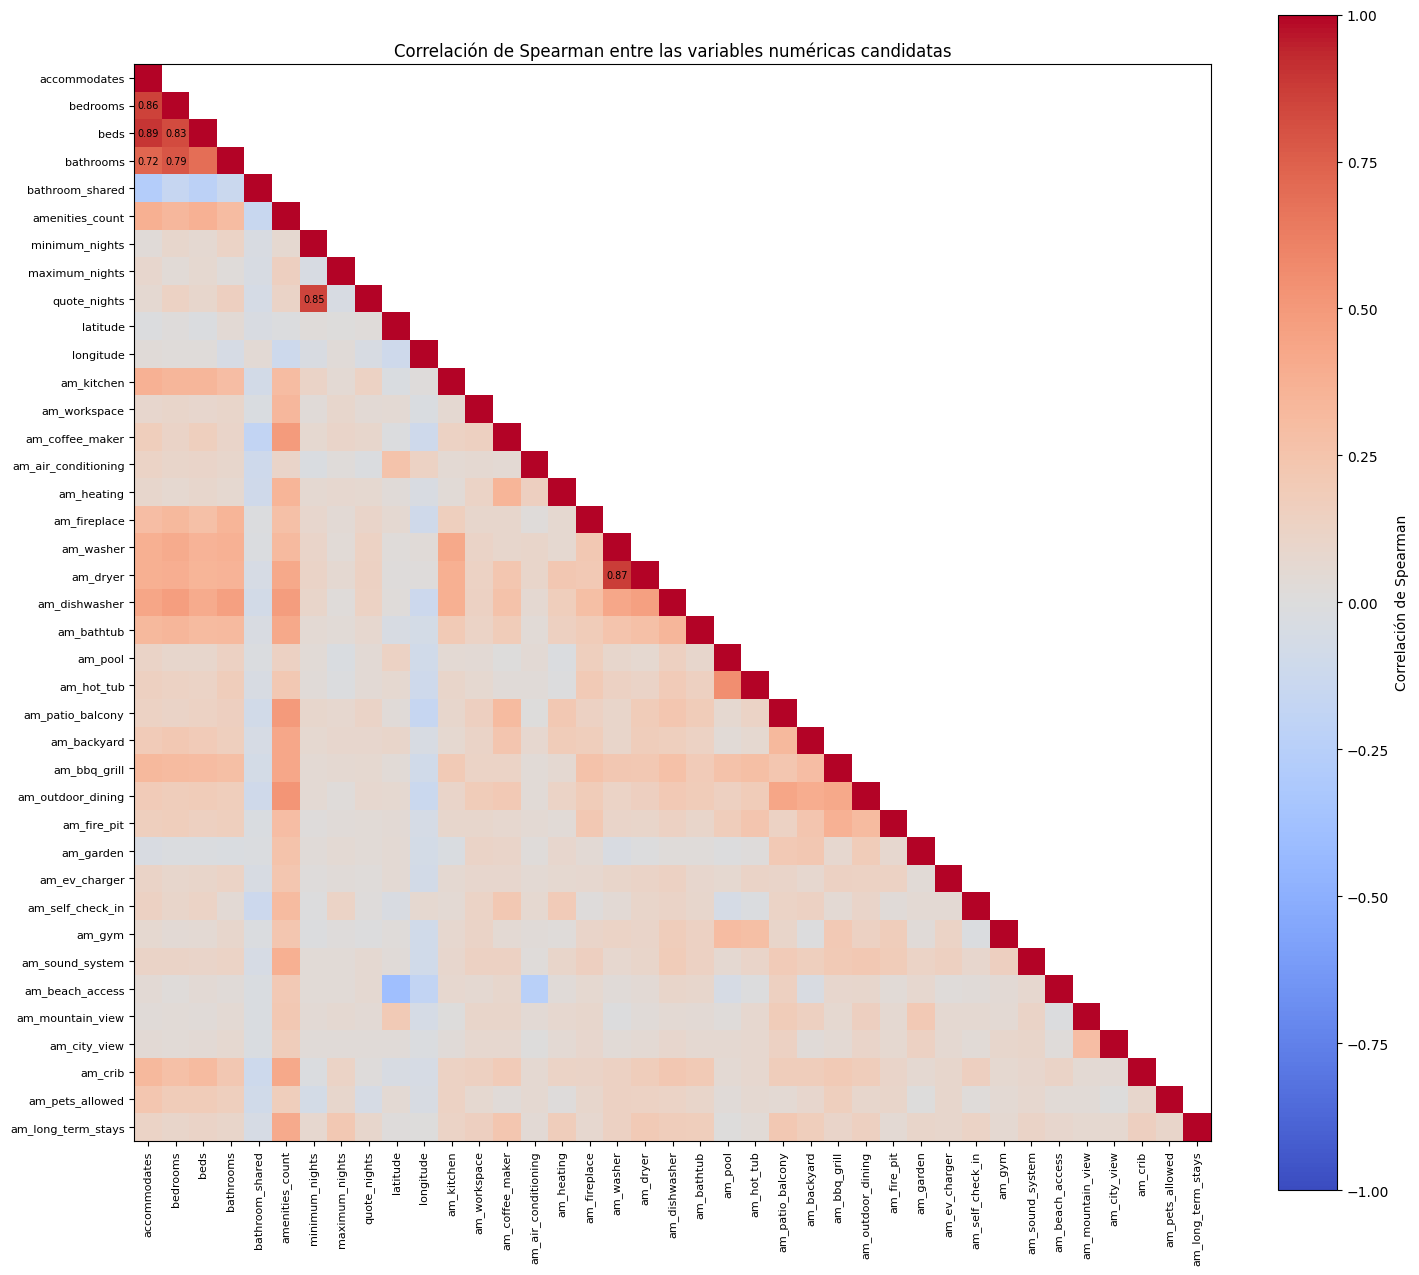

In [31]:
import matplotlib.pyplot as plt

# Correlación de Spearman entre las variables numéricas (mitad inferior); se rotulan las parejas con |ρ| ≥ 0,7
spearman_matrix = df_limpio[NUMERIC_CANDIDATES].corr(method='spearman')
values = spearman_matrix.to_numpy()
masked = np.ma.masked_where(np.triu(np.ones_like(values, dtype=bool), k=1) | ~np.isfinite(values), values)
cmap = plt.get_cmap('coolwarm').copy()
cmap.set_bad('white')

n_vars = len(NUMERIC_CANDIDATES)
fig, ax = plt.subplots(figsize=(15, 13))
image = ax.imshow(masked, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(n_vars), NUMERIC_CANDIDATES, rotation=90, fontsize=8)
ax.set_yticks(range(n_vars), NUMERIC_CANDIDATES, fontsize=8)
for i in range(n_vars):
    for j in range(i):
        if abs(values[i, j]) >= 0.7:
            ax.text(j, i, f'{values[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(image, ax=ax, label='Correlación de Spearman')
ax.set_title('Correlación de Spearman entre las variables numéricas candidatas')
plt.tight_layout()
plt.show()

### 4.2 · Dejar solo la variable que mejor explica el precio
**Regla:** si dos variables tienen una correlación de **|ρ| ≥ 0,8** entre ellas, se conserva la que tiene **mayor |Spearman| con el precio original** y se elimina la otra. Las parejas se revisan de la más correlacionada a la menos.

**Excepción:** `accommodates` (capacidad) y `bedrooms` (habitaciones) son características obligatorias del Project Charter y entradas del tablero, así que no se eliminan aunque estén correlacionadas entre sí; la pareja se reporta.

**Categóricas anidadas:** si dos variables categóricas tienen una asociación de **V de Cramér ≥ 0,8** (una casi determina a la otra), se conserva la de mayor η con el precio.

In [32]:
CORR_THRESHOLD = 0.8
PROTECTED = {'accommodates', 'bedrooms'}            # características obligatorias del Project Charter
strength = corr_table['fuerza (|Spearman| o η)']

# Parejas numéricas muy correlacionadas, de mayor a menor
pairs = []
for i, a in enumerate(NUMERIC_CANDIDATES):
    for b in NUMERIC_CANDIDATES[i + 1:]:
        rho = spearman_matrix.loc[a, b]
        if abs(rho) >= CORR_THRESHOLD:
            pairs.append((a, b, rho))

# Parejas categóricas: V de Cramér
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

for i, a in enumerate(CATEGORICAL_CANDIDATES):
    for b in CATEGORICAL_CANDIDATES[i + 1:]:
        v = cramers_v(df_limpio[a], df_limpio[b])
        if v >= CORR_THRESHOLD:
            pairs.append((a, b, v))

dropped, decisions = set(), []
for a, b, assoc in sorted(pairs, key=lambda t: -abs(t[2])):
    if a in dropped or b in dropped:
        decisions.append((a, b, assoc, '—', 'Ya se eliminó una de las dos'))
        continue
    if {a, b} <= PROTECTED:
        decisions.append((a, b, assoc, '—', 'Se conservan ambas (Project Charter)'))
        continue
    keep, drop = (a, b) if strength[a] >= strength[b] else (b, a)
    if drop in PROTECTED:
        keep, drop = drop, keep
    dropped.add(drop)
    decisions.append((a, b, assoc, drop, f'Se conserva {keep} ({strength[keep]:.3f} vs {strength[drop]:.3f})'))

decision_table = pd.DataFrame(decisions, columns=['variable 1', 'variable 2', 'asociación', 'se elimina', 'motivo'])
display(decision_table.round(3))

SELECTED_NUMERIC = [c for c in NUMERIC_CANDIDATES if c not in dropped]
SELECTED_CATEGORICAL = [c for c in CATEGORICAL_CANDIDATES if c not in dropped]
SELECTED_FEATURES = SELECTED_NUMERIC + SELECTED_CATEGORICAL
print(f'Variables eliminadas ({len(dropped)}): {sorted(dropped)}')
print(f'Variables seleccionadas ({len(SELECTED_FEATURES)}): {len(SELECTED_NUMERIC)} numéricas y {len(SELECTED_CATEGORICAL)} categóricas')
print(SELECTED_FEATURES)

,variable 1,variable 2,asociación,se elimina,motivo
0,property_type_model,room_type,1.000,room_type,Se conserva property_type_model (0.564 vs 0.338)
1,neighbourhood_model,neighbourhood_group_cleansed,0.992,neighbourhood_group_cleansed,Se conserva neighbourhood_model (0.501 vs 0.211)
2,accommodates,beds,0.892,beds,Se conserva accommodates (0.695 vs 0.638)
3,am_washer,am_dryer,0.873,am_washer,Se conserva am_dryer (0.340 vs 0.337)
4,accommodates,bedrooms,0.856,—,Se conservan ambas (Project Charter)
5,minimum_nights,quote_nights,0.850,minimum_nights,Se conserva quote_nights (0.047 vs 0.037)
6,bedrooms,beds,0.827,—,Ya se eliminó una de las dos


Variables eliminadas (5): ['am_washer', 'beds', 'minimum_nights', 'neighbourhood_group_cleansed', 'room_type']
Variables seleccionadas (38): 36 numéricas y 2 categóricas
['accommodates', 'bedrooms', 'bathrooms', 'bathroom_shared', 'amenities_count', 'maximum_nights', 'quote_nights', 'latitude', 'longitude', 'am_kitchen', 'am_workspace', 'am_coffee_maker', 'am_air_conditioning', 'am_heating', 'am_fireplace', 'am_dryer', 'am_dishwasher', 'am_bathtub', 'am_pool', 'am_hot_tub', 'am_patio_balcony', 'am_backyard', 'am_bbq_grill', 'am_outdoor_dining', 'am_fire_pit', 'am_garden', 'am_ev_charger', 'am_self_check_in', 'am_gym', 'am_sound_system', 'am_beach_access', 'am_mountain_view', 'am_city_view', 'am_crib', 'am_pets_allowed', 'am_long_term_stays', 'neighbourhood_model', 'property_type_model']


### 4.3 · ANOVA de cada variable (Daniel Babativa)
Para cada variable candidata se ajusta una regresión del precio con esa sola variable y se hace un **ANOVA tipo II con errores robustos (HC3)**. Como se prueban muchas variables a la vez, los valores p se ajustan con **Holm**. Las variables seleccionadas en 4.2 que **no** son significativas al 5 % se eliminan.

In [33]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests

resultados = []

for variable in NUMERIC_CANDIDATES + CATEGORICAL_CANDIDATES:
    es_categorica = variable in CATEGORICAL_CANDIDATES
    termino = f"C({variable})" if es_categorica else variable

    datos = df_limpio[["price_num", variable]].dropna()

    if datos[variable].nunique() < 2:
        continue

    modelo = ols(f"price_num ~ {termino}", data=datos).fit()
    tabla = anova_lm(modelo, typ=2, robust="hc3")

    resultados.append({
        "variable": variable,
        "tipo": "categórica" if es_categorica else "numérica/binaria",
        "anuncios": len(datos),
        "estadístico_F": tabla.loc[termino, "F"],
        "p_valor": tabla.loc[termino, "PR(>F)"],
        "R2": modelo.rsquared
    })

tabla_significancia = pd.DataFrame(resultados)

# Ajustar por probar muchas variables
tabla_significancia["p_ajustado"] = multipletests(
    tabla_significancia["p_valor"],
    method="holm"
)[1]

tabla_significancia["significativa_5%"] = (
    tabla_significancia["p_ajustado"] < 0.05
)

display(
    tabla_significancia
    .sort_values("p_ajustado")
    .round(4)
)


,variable,tipo,anuncios,estadístico_F,p_valor,R2,p_ajustado,significativa_5%
0,accommodates,numérica/binaria,7327,2375.4213,0.0000,0.3764,0.0000,True
1,bedrooms,numérica/binaria,7327,2763.0706,0.0000,0.4202,0.0000,True
4,bathroom_shared,numérica/binaria,7327,1755.9333,0.0000,0.0385,0.0000,True
42,room_type,categórica,7327,1378.3026,0.0000,0.1140,0.0000,True
41,property_type_model,categórica,7327,228.1252,0.0000,0.3175,0.0000,True
19,am_dishwasher,numérica/binaria,7327,1532.1533,0.0000,0.1739,0.0000,True
11,am_kitchen,numérica/binaria,7327,1486.1822,0.0000,0.0665,0.0000,True
39,neighbourhood_model,categórica,7327,10.4175,0.0000,0.2510,0.0000,True
17,am_washer,numérica/binaria,7327,1146.0548,0.0000,0.0839,0.0000,True
18,am_dryer,numérica/binaria,7327,937.1765,0.0000,0.0827,0.0000,True


In [34]:
not_significant = set(tabla_significancia.loc[~tabla_significancia['significativa_5%'], 'variable'])
removed = [c for c in SELECTED_FEATURES if c in not_significant]

SELECTED_FEATURES = [c for c in SELECTED_FEATURES if c not in not_significant]
SELECTED_NUMERIC = [c for c in SELECTED_NUMERIC if c not in not_significant]
SELECTED_CATEGORICAL = [c for c in SELECTED_CATEGORICAL if c not in not_significant]

print(f'Variables no significativas que se eliminan ({len(removed)}): {removed if removed else "ninguna"}')
print(f'Variables finales ({len(SELECTED_FEATURES)}): {len(SELECTED_NUMERIC)} numéricas y {len(SELECTED_CATEGORICAL)} categóricas')

Variables no significativas que se eliminan (1): ['maximum_nights']
Variables finales (37): 35 numéricas y 2 categóricas


### 4.4 · ¿A qué distribución se ajusta el precio?
Se compara el precio original con su logaritmo:
- **Asimetría:** 0 en una distribución simétrica.
- **Kolmogorov-Smirnov (KS):** distancia máxima a una normal con la misma media y desviación (D más pequeño = más parecido).
- **Shapiro-Wilk:** sobre una muestra de 5.000 anuncios (W más cercano a 1 = más parecido a la normal).
- **Gráficas:** histograma con la normal superpuesta, Q-Q y P-P.

Con miles de datos las pruebas casi siempre rechazan la normalidad exacta; lo que importa es **cuál escala se acerca más**.

In [35]:
from scipy import stats
rng = np.random.default_rng(SEED)

def normality(values):
    mu, sd = values.mean(), values.std(ddof=1)
    ks = stats.kstest(values, stats.norm(mu, sd).cdf)
    sample = rng.choice(values, size=min(len(values), 5000), replace=False)
    sw = stats.shapiro(sample)
    return {'asimetría': stats.skew(values), 'KS D': ks.statistic, 'KS valor p': ks.pvalue,
            'Shapiro W': sw.statistic, 'Shapiro valor p': sw.pvalue}

p = df_limpio['price_num'].to_numpy()
original, logged = normality(p), normality(np.log(p))
USE_LOG = abs(logged['asimetría']) < abs(original['asimetría']) and logged['KS D'] < original['KS D']
distribution_table = pd.DataFrame([original, logged], index=['precio original', 'log(precio)'])
display(distribution_table.round(4))
print(f'Recomendación: usar el precio {"en logaritmo" if USE_LOG else "original"}')

,asimetría,KS D,KS valor p,Shapiro W,Shapiro valor p
precio original,1.9731,0.1418,0.0000,0.8260,0.0
log(precio),0.0960,0.0202,0.0051,0.9974,0.0


Recomendación: usar el precio en logaritmo


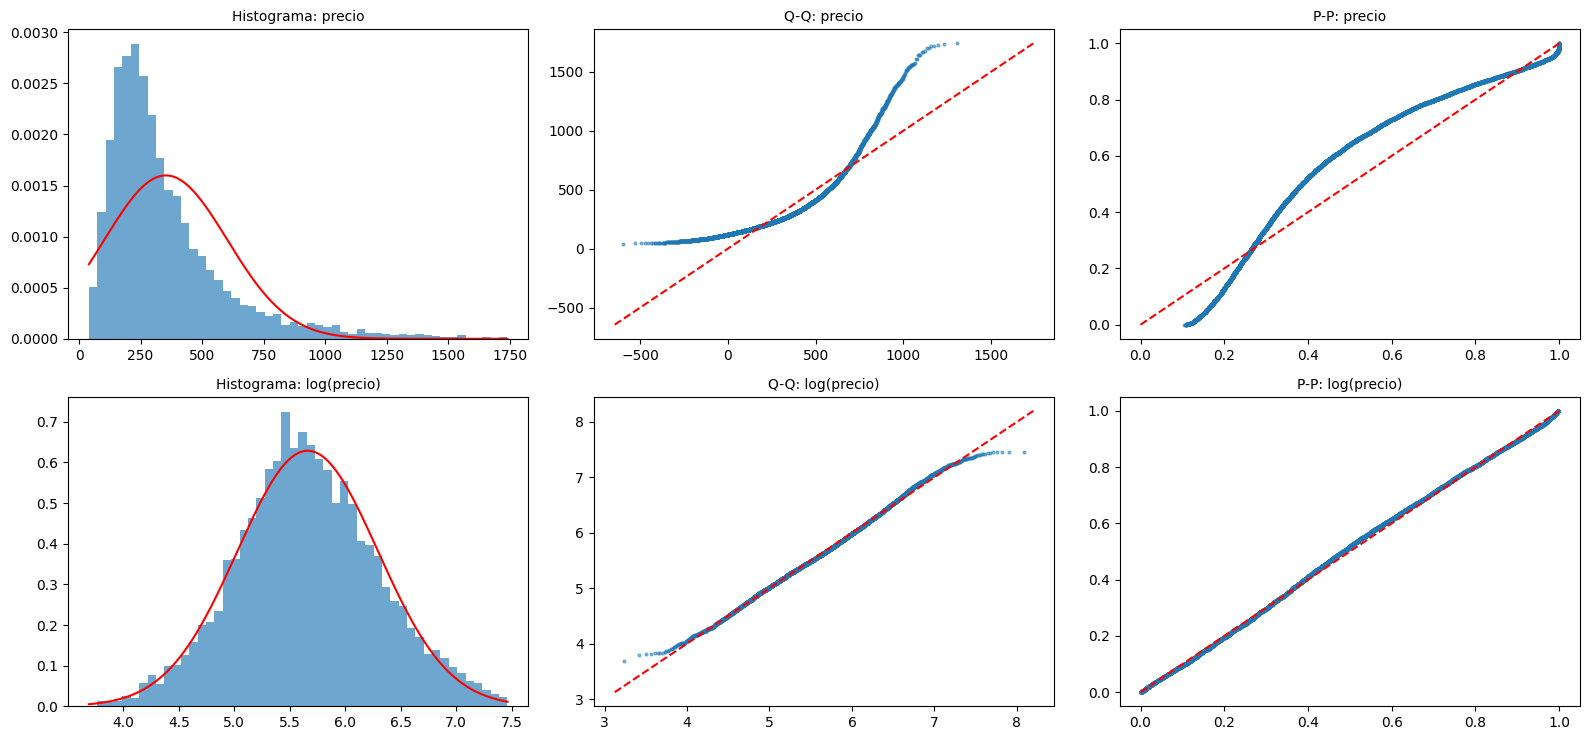

In [36]:
def plot_normality(ax_row, values, title):
    values = np.sort(values)
    mu, sd = values.mean(), values.std(ddof=1)
    probs = (np.arange(1, len(values) + 1) - 0.5) / len(values)
    ax_row[0].hist(values, bins=50, density=True, alpha=0.65)
    x = np.linspace(values.min(), values.max(), 300)
    ax_row[0].plot(x, stats.norm.pdf(x, mu, sd), 'r')
    ax_row[0].set_title(f'Histograma: {title}', fontsize=10)
    ax_row[1].scatter(stats.norm.ppf(probs, mu, sd), values, s=4, alpha=0.5)
    lims = [min(values.min(), mu - 4 * sd), max(values.max(), mu + 4 * sd)]
    ax_row[1].plot(lims, lims, 'r--')
    ax_row[1].set_title(f'Q-Q: {title}', fontsize=10)
    ax_row[2].scatter(stats.norm.cdf(values, mu, sd), probs, s=4, alpha=0.5)
    ax_row[2].plot([0, 1], [0, 1], 'r--')
    ax_row[2].set_title(f'P-P: {title}', fontsize=10)

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
plot_normality(axes[0], p, 'precio')
plot_normality(axes[1], np.log(p), 'log(precio)')
plt.tight_layout()
plt.show()

### 4.5 · DataFrame final para el modelo
`df_modelo` contiene:
- `id`,
- la variable objetivo: `price_num` y `price_log`,
- `ocupacion` (noches ocupadas en los últimos 12 meses): **no es predictor**, se usa solo para validar la clasificación (sección 9.3),
- las **variables seleccionadas** en las secciones 4.2 y 4.3.

In [37]:
# Anuncios sin noches mínimas o máximas: mínimas = noches cotizadas (coinciden en la gran mayoría, sección 3.1);
# máximas = mediana. Se marca con nights_imputed.
df_limpio['nights_imputed'] = df_limpio['minimum_nights'].isna().astype(int)
df_limpio['minimum_nights'] = df_limpio['minimum_nights'].fillna(df_limpio['quote_nights'])
df_limpio['maximum_nights'] = df_limpio['maximum_nights'].fillna(df_limpio['maximum_nights'].median())
print(f"Noches mínimas/máximas rellenadas: {df_limpio['nights_imputed'].sum()} anuncios")

df_modelo = df_limpio[['id', 'price_num'] + SELECTED_FEATURES].copy()
df_modelo.insert(2, 'price_log', np.log(df_modelo['price_num']))
df_modelo.insert(3, 'ocupacion', df_limpio['estimated_occupancy_l365d'].to_numpy())
constant = [c for c in SELECTED_FEATURES if df_modelo[c].nunique(dropna=False) <= 1]
df_modelo = df_modelo.drop(columns=constant).reset_index(drop=True)
assert df_modelo.drop(columns=['id']).isna().sum().sum() == 0, 'Hay vacíos en df_modelo'

n_pred = df_modelo.shape[1] - 4
print(f'df_modelo: {df_modelo.shape}')
print(f'  Contiene: {len(df_modelo):,} anuncios diarios y activos de hosts con 1–2 anuncios.')
print(f'  Variable objetivo: price_num (dólares por noche) y price_log (su logaritmo).')
print(f'  Predictores: {n_pred} variables seleccionadas en 4.2 y 4.3.')

Noches mínimas/máximas rellenadas: 9 anuncios
df_modelo: (7327, 41)
  Contiene: 7,327 anuncios diarios y activos de hosts con 1–2 anuncios.
  Variable objetivo: price_num (dólares por noche) y price_log (su logaritmo).
  Predictores: 37 variables seleccionadas en 4.2 y 4.3.


## 5 · Modelo de regresión (metodología del TEC)
Se repite **exactamente la metodología de regresión del equipo del TEC** (notebook `LA_LA_Stay_.ipynb` de la rama `main`, sección 4), aplicada a `df_modelo`:

| Paso | Igual al TEC |
|---|---|
| Modelo | `Ridge` dentro de un `Pipeline` con `OneHotEncoder(handle_unknown='ignore')` para las categóricas |
| Variable objetivo | Precio por noche en dólares **sin transformar** (`price_num`) |
| División | El TEC usó 80 % / 20 %; aquí Ridge aprende con el 85 % (entrenamiento + validación) y se evalúa en el mismo 15 % de prueba que los demás modelos (sección 5.2), `random_state=42` |
| Elección de `alpha` | Validación cruzada de 3 partes (`KFold`, `shuffle=True`, `random_state=42`) sobre entrenamiento, con `alpha` ∈ {1, 10, 100} |
| Evaluación | MAE, RMSE y R² en prueba; meta de R² ≥ 0,30; precio real vs. predicción; distribución de errores; error por rango de precio |

**Lo único que cambia son los datos:** en lugar de su base (14.825 anuncios que mezclan precios diarios y mensuales) se usan los anuncios diarios y activos de `df_modelo` con las variables seleccionadas en la sección 4.

### 5.1 · Preparar las variables

In [38]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NON_FEATURES = ['id', 'price_num', 'price_log', 'ocupacion']
BASE_FEATURES = [c for c in df_modelo.columns if c not in NON_FEATURES]
CATEGORICAL = [c for c in BASE_FEATURES if df_modelo[c].dtype == 'object']
X, y = df_modelo[BASE_FEATURES], df_modelo['price_num']
print(f'df_modelo: {len(df_modelo):,} anuncios | {len(BASE_FEATURES)} variables '
      f'({len(BASE_FEATURES) - len(CATEGORICAL)} numéricas, {len(CATEGORICAL)} categóricas) | objetivo = price_num (USD)')

df_modelo: 7,327 anuncios | 37 variables (35 numéricas, 2 categóricas) | objetivo = price_num (USD)


### 5.2 · Separar entrenamiento, validación y prueba (70 / 15 / 15)
Una sola división para todo el notebook (`SEED = 42`):

| Conjunto | % | Uso |
|---|---|---|
| **Entrenamiento** | 70 % | Aprender los parámetros |
| **Validación** | 15 % | Elegir hiperparámetros de la red neuronal (sección 7.3) |
| **Prueba** | 15 % | Medir **una sola vez** a los modelos finales con anuncios que nunca vieron |

Los modelos lineales (Ridge y Lasso) eligen `alpha` con **validación cruzada de 3 partes** (metodología del TEC), así que usan entrenamiento + validación juntos (85 %) y no necesitan un conjunto de validación aparte. Así los dos modelos finales aprenden y se ajustan con el mismo 85 % y se comparan en el mismo 15 % de prueba.

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)       # 85 % / 15 %
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.15 / 0.85, random_state=SEED)  # 70 % / 15 %
print(f'Entrenamiento: {len(X_fit):,} ({len(X_fit) / len(X):.0%}) | Validación: {len(X_val):,} ({len(X_val) / len(X):.0%}) | '
      f'Prueba: {len(X_test):,} ({len(X_test) / len(X):.0%})')
print(f'Entrenamiento + validación (modelos lineales con validación cruzada): {len(X_train):,}')

Entrenamiento: 5,128 (70%) | Validación: 1,099 (15%) | Prueba: 1,100 (15%)
Entrenamiento + validación (modelos lineales con validación cruzada): 6,227


### 5.3 · Supuestos de la regresión lineal
Antes de usar una regresión lineal se revisa si los datos cumplen sus supuestos. Para eso se ajusta una regresión lineal por **mínimos cuadrados ordinarios (MCO)** con las mismas variables del modelo (categóricas con variables indicadoras) sobre el conjunto de entrenamiento + validación, con dos variables objetivo: el **precio en dólares** (como el TEC) y el **log(precio)**.

| Supuesto | Qué significa | Cómo se revisa |
|---|---|---|
| **Linealidad** | La relación entre las variables predictoras (X) y la variable dependiente (Y) es lineal | Residuos vs. valores ajustados (no debe haber curvas) y prueba **RESET de Ramsey** |
| **Independencia de los errores** | Los residuos no están correlacionados entre sí (no hay autocorrelación) | Prueba de **Durbin-Watson** (≈ 2 = sin autocorrelación) |
| **Homocedasticidad** | La varianza de los errores es constante para todos los niveles de las variables predictoras | Residuos vs. ajustados (no debe haber forma de embudo) y prueba de **Breusch-Pagan** |
| **Normalidad de los residuos** | Los errores del modelo siguen una distribución normal | **Q-Q plot**, **Shapiro-Wilk** (muestra de 5.000) y **Jarque-Bera** |
| **No multicolinealidad** | Las variables independientes no tienen correlación alta ni exacta entre sí | **Factor de inflación de varianza (VIF)**: > 10 indica multicolinealidad fuerte |

En todas las pruebas la hipótesis nula es que **el supuesto se cumple**; un valor p < 0,05 indica que no se cumple.

Referencias: [RPubs · supuestos de regresión](https://rpubs.com/jfzeac/Clase25_supuestos_regresion), [RPubs · SMRL](https://rpubs.com/JairoAyala/SMRL), [JMP · supuestos de la regresión lineal](https://www.jmp.com/es/statistics-knowledge-portal/linear-models/what-is-regression/simple-linear-regression-assumptions).

In [40]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Matriz de diseño: numéricas + indicadoras de las categóricas (se quita una categoría para evitar colinealidad exacta)
X_ols = pd.get_dummies(X_train, columns=CATEGORICAL, drop_first=True, dtype=float)
X_ols = X_ols.loc[:, X_ols.std() > 0]
X_ols = sm.add_constant(X_ols)

ols_models = {'precio (USD)': sm.OLS(y_train, X_ols).fit(),
              'log(precio)': sm.OLS(np.log(y_train), X_ols).fit()}

rng_sw = np.random.default_rng(SEED)
assumption_rows = []
for target_name, fit in ols_models.items():
    resid, fitted = fit.resid, fit.fittedvalues
    reset = linear_reset(fit, power=2, use_f=True)
    bp = het_breuschpagan(resid, fit.model.exog)
    sw = stats.shapiro(rng_sw.choice(resid, size=min(len(resid), 5000), replace=False))
    jb = jarque_bera(resid)
    dw = durbin_watson(resid)
    assumption_rows += [
        {'objetivo': target_name, 'supuesto': 'Linealidad', 'prueba': 'RESET de Ramsey (F)', 'estadístico': float(reset.fvalue), 'valor p': float(reset.pvalue)},
        {'objetivo': target_name, 'supuesto': 'Independencia', 'prueba': 'Durbin-Watson', 'estadístico': dw, 'valor p': np.nan},
        {'objetivo': target_name, 'supuesto': 'Homocedasticidad', 'prueba': 'Breusch-Pagan (LM)', 'estadístico': bp[0], 'valor p': bp[1]},
        {'objetivo': target_name, 'supuesto': 'Normalidad', 'prueba': 'Shapiro-Wilk (W)', 'estadístico': sw.statistic, 'valor p': sw.pvalue},
        {'objetivo': target_name, 'supuesto': 'Normalidad', 'prueba': 'Jarque-Bera', 'estadístico': jb[0], 'valor p': jb[1]},
    ]

assumptions = pd.DataFrame(assumption_rows)
def verdict(r):
    if r['prueba'] == 'Durbin-Watson':
        return 'Se cumple' if 1.5 <= r['estadístico'] <= 2.5 else 'No se cumple'
    return 'Se cumple' if r['valor p'] >= 0.05 else 'No se cumple'
assumptions['conclusión (5 %)'] = assumptions.apply(verdict, axis=1)
print(f"Regresión MCO: {int(ols_models['precio (USD)'].df_model)} variables | {len(y_train):,} anuncios | "
      f"R² (precio) = {ols_models['precio (USD)'].rsquared:.3f} | R² (log) = {ols_models['log(precio)'].rsquared:.3f}")
assumptions.set_index(['objetivo', 'supuesto']).round(4)

Regresión MCO: 264 variables | 6,227 anuncios | R² (precio) = 0.725 | R² (log) = 0.797


prueba  estadístico  valor p  \
objetivo     supuesto                                                      
precio (USD) Linealidad        RESET de Ramsey (F)     705.7001      0.0   
             Independencia           Durbin-Watson       1.9995      NaN   
             Homocedasticidad   Breusch-Pagan (LM)    1148.3404      0.0   
             Normalidad           Shapiro-Wilk (W)       0.9071      0.0   
             Normalidad                Jarque-Bera   14615.7475      0.0   
log(precio)  Linealidad        RESET de Ramsey (F)      16.7505      0.0   
             Independencia           Durbin-Watson       2.0145      NaN   
             Homocedasticidad   Breusch-Pagan (LM)     543.6023      0.0   
             Normalidad           Shapiro-Wilk (W)       0.9945      0.0   
             Normalidad                Jarque-Bera    1104.0135      0.0   

                              conclusión (5 %)  
objetivo     supuesto                           
precio (USD) Linealidad           No se cumple  
             Independencia           Se cumple  
             Homocedasticidad     No se cumple  
             Normalidad           No se cumple  
             Normalidad           No se cumple  
log(precio)  Linealidad           No se cumple  
             Independencia           Se cumple  
             Homocedasticidad     No se cumple  
             Normalidad           No se cumple  
             Normalidad           No se cumple

**Gráficas de residuos.** Izquierda: residuos vs. valores ajustados (linealidad y homocedasticidad: los puntos deberían formar una nube horizontal pareja alrededor de 0, la línea roja es una tendencia suavizada). Centro: Q-Q plot (normalidad: los puntos deberían seguir la diagonal). Derecha: histograma de los residuos con la normal superpuesta.

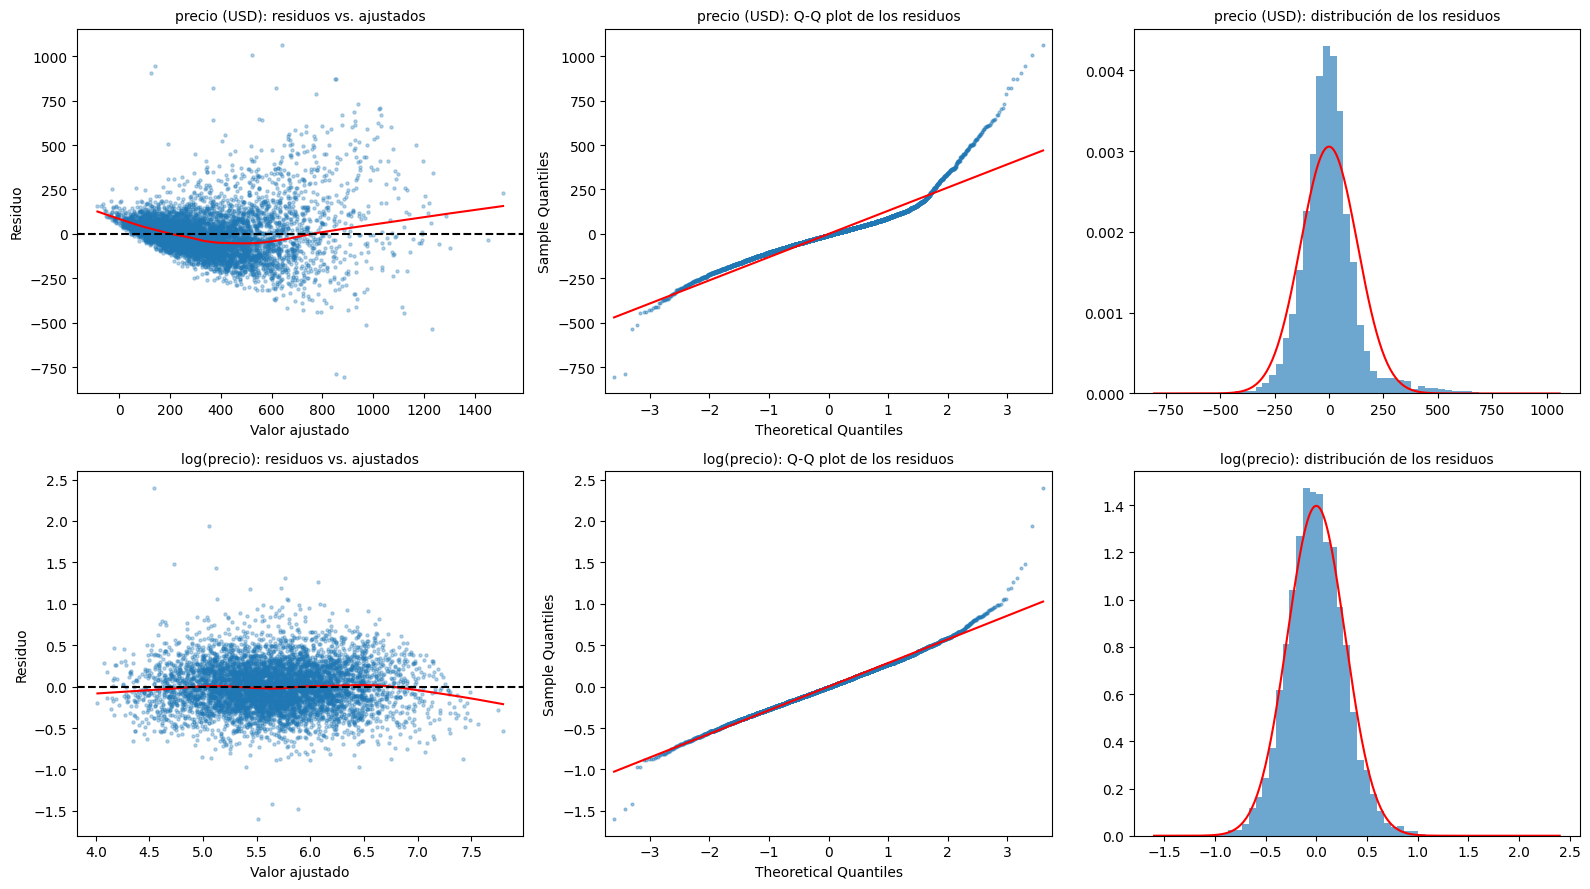

In [41]:
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, (target_name, fit) in zip(axes, ols_models.items()):
    resid, fitted = fit.resid, fit.fittedvalues
    row[0].scatter(fitted, resid, s=5, alpha=0.3)
    smooth = lowess(resid, fitted, frac=0.3)
    row[0].plot(smooth[:, 0], smooth[:, 1], color='red')
    row[0].axhline(0, linestyle='--', color='black')
    row[0].set_title(f'{target_name}: residuos vs. ajustados', fontsize=10)
    row[0].set_xlabel('Valor ajustado'); row[0].set_ylabel('Residuo')
    sm.qqplot(resid, line='s', ax=row[1], markersize=2, alpha=0.4)
    row[1].set_title(f'{target_name}: Q-Q plot de los residuos', fontsize=10)
    row[2].hist(resid, bins=60, density=True, alpha=0.65)
    x = np.linspace(resid.min(), resid.max(), 300)
    row[2].plot(x, stats.norm.pdf(x, resid.mean(), resid.std()), 'r')
    row[2].set_title(f'{target_name}: distribución de los residuos', fontsize=10)
plt.tight_layout()
plt.show()

**Multicolinealidad (VIF).** Se calcula para las variables numéricas: VIF = 1 / (1 − R²) de la regresión de cada variable contra las demás. Valores mayores a 5 indican multicolinealidad moderada y mayores a 10, fuerte.

,VIF,nivel
bedrooms,5.35,moderado (5–10)
amenities_count,4.93,bajo (< 5)
accommodates,4.60,bajo (< 5)
bathrooms,2.76,bajo (< 5)
am_dishwasher,1.73,bajo (< 5)
am_outdoor_dining,1.65,bajo (< 5)
am_hot_tub,1.58,bajo (< 5)
am_bbq_grill,1.57,bajo (< 5)
am_pool,1.54,bajo (< 5)
am_coffee_maker,1.53,bajo (< 5)


Variables con VIF > 10: 0 | entre 5 y 10: 1 | VIF máximo: 5.35 (bedrooms)


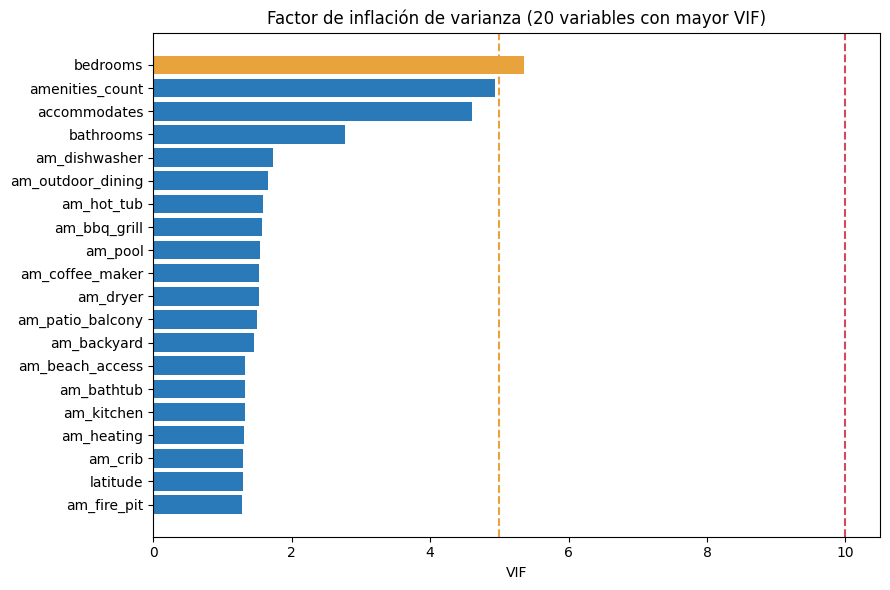

In [42]:
vif_X = sm.add_constant(X_train[[c for c in BASE_FEATURES if c not in CATEGORICAL]])
vif = pd.Series([variance_inflation_factor(vif_X.values, i) for i in range(1, vif_X.shape[1])],
                index=vif_X.columns[1:]).sort_values(ascending=False)
vif_table = vif.to_frame('VIF')
vif_table['nivel'] = pd.cut(vif_table['VIF'], [0, 5, 10, np.inf], labels=['bajo (< 5)', 'moderado (5–10)', 'fuerte (> 10)'])
display(vif_table.head(12).round(2))
print(f"Variables con VIF > 10: {int((vif > 10).sum())} | entre 5 y 10: {int(vif.between(5, 10).sum())} | "
      f"VIF máximo: {vif.max():.2f} ({vif.idxmax()})")

top = vif.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 10, '#d1495b', np.where(top.values > 5, '#e8a33d', '#2a7ab9')))
ax.axvline(5, linestyle='--', color='#e8a33d'); ax.axvline(10, linestyle='--', color='#d1495b')
ax.set_xlabel('VIF')
ax.set_title('Factor de inflación de varianza (20 variables con mayor VIF)')
plt.tight_layout()
plt.show()

**Qué se concluye de los supuestos**

| Supuesto | Precio (USD) | log(precio) |
|---|---|---|
| Linealidad | **No se cumple:** la curva de residuos tiene forma de U y la prueba RESET rechaza con fuerza (F ≈ 706) | Mucho más cerca: la curva es casi plana (F ≈ 17), aunque la prueba sigue rechazando |
| Independencia | **Se cumple:** Durbin-Watson ≈ 2,00 | **Se cumple:** Durbin-Watson ≈ 2,01 |
| Homocedasticidad | **No se cumple:** los residuos se abren en forma de embudo a medida que sube el precio (Breusch-Pagan LM ≈ 1.148) | Mejora mucho (LM ≈ 544) y la nube es pareja, pero la prueba sigue rechazando |
| Normalidad | **No se cumple:** cola derecha larga en el Q-Q plot (Shapiro W = 0,907) | Casi normal: el Q-Q sigue la diagonal salvo los extremos (W = 0,995) |
| No multicolinealidad | **Se cumple:** ningún VIF supera 10; el mayor es `bedrooms` (≈ 5,4), correlacionada con `accommodates` | Igual (el VIF no depende de la variable objetivo) |

- Con el precio en dólares, como lo usa el TEC, la regresión lineal **incumple linealidad, homocedasticidad y normalidad**. Esto respalda usar **log(precio)** (Modelo A) y probar un modelo **no lineal** (red neuronal, Modelo B).
- Con más de 6.000 anuncios las pruebas detectan desviaciones muy pequeñas; por eso se leen junto con las gráficas, que en log muestran residuos casi normales y con varianza pareja.
- Para **predecir**, incumplir estos supuestos no invalida el modelo: los coeficientes siguen siendo insesgados, pero sus errores estándar y valores p no son confiables. Si se quisiera interpretar coeficientes, habría que usar errores robustos (HC3).
- Los datos son de corte transversal (un anuncio por fila, sin orden en el tiempo), así que la independencia es razonable; Durbin-Watson lo confirma.

### 5.4 · Convertir los textos en variables numéricas
Ridge no entiende nombres de vecindarios directamente. `OneHotEncoder` crea indicadores numéricos y `handle_unknown='ignore'` permite recibir categorías nuevas en el futuro.

In [43]:
def tec_pipeline(category_features, alpha=1):
    preprocessor = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), category_features)
    ], remainder='passthrough')
    return Pipeline([('prepare', preprocessor), ('ridge', Ridge(alpha=alpha))])

tec_model = tec_pipeline(CATEGORICAL)
print('Ridge pipeline ready')

Ridge pipeline ready


### 5.5 · Comprobar si Ridge es una elección razonable
Se prueban distintas intensidades de regularización con **validación cruzada sobre entrenamiento + validación**. La prueba permanece apartada, para no escoger el modelo mirando su calificación final.

,alpha,CV_R2
0,1,0.6976
1,10,0.6938
2,100,0.6567


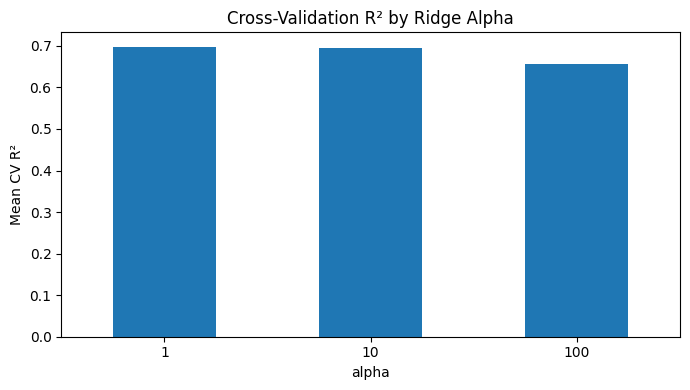

In [44]:
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for alpha in [1, 10, 100]:
    tec_model.set_params(ridge__alpha=alpha)
    scores = cross_val_score(tec_model, X_train, y_train, cv=cv, scoring='r2')
    cv_rows.append({'alpha': alpha, 'CV_R2': scores.mean()})
cv_table = pd.DataFrame(cv_rows).sort_values('CV_R2', ascending=False)
display(cv_table.round(4))

cv_table.sort_values('alpha').plot.bar(x='alpha', y='CV_R2', legend=False, figsize=(7, 4))
plt.title('Cross-Validation R² by Ridge Alpha')
plt.ylabel('Mean CV R²')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretación:** el mejor `alpha` es el que obtuvo mayor R² promedio **solo en entrenamiento**. No es una garantía de que el R² final sea idéntico.

### 5.6 · Entrenar el modelo elegido

In [45]:
best_alpha = int(cv_table.iloc[0]['alpha'])
tec_model.set_params(ridge__alpha=best_alpha)
tec_model.fit(X_train, y_train)
print(f'Selected alpha: {best_alpha} | model trained')

Selected alpha: 1 | model trained


### 5.7 · Predecir y evaluar
MAE y RMSE en dólares; R² indica qué proporción de la variación de precios se explica en **el conjunto de prueba**. Como referencia se incluye el resultado original del TEC con su base (que no es el mismo examen: su prueba mezcla precios diarios y mensuales).

In [46]:
y_pred_tec = tec_model.predict(X_test)
r2 = r2_score(y_test, y_pred_tec)
evaluation = pd.DataFrame([
    {'datos': 'Diarios y activos (df_modelo)', 'alpha': best_alpha, 'train': len(X_train), 'test': len(X_test),
     'MAE ($)': mean_absolute_error(y_test, y_pred_tec), 'RMSE ($)': np.sqrt(mean_squared_error(y_test, y_pred_tec)),
     'R²': r2, 'R² ≥ 0.30': r2 >= 0.30, 'predicciones negativas': int((y_pred_tec < 0).sum())},
    {'datos': 'TEC original (su base)', 'alpha': 1, 'train': 11860, 'test': 2965,
     'MAE ($)': 121.99, 'RMSE ($)': 193.93, 'R²': 0.5749, 'R² ≥ 0.30': True, 'predicciones negativas': np.nan},
]).set_index('datos')
evaluation.round(4)

,alpha,train,test,MAE ($),RMSE ($),R²,R² ≥ 0.30,predicciones negativas
datos,,,,,,,,
Diarios y activos (df_modelo),1,6227,1100,92.1893,132.8092,0.7226,True,7.0
TEC original (su base),1,11860,2965,121.9900,193.9300,0.5749,True,NaN


**Cómo se explica:** si el MAE es $120, el error absoluto promedio es aproximadamente 120 dólares por noche. **R² no es un porcentaje de predicciones correctas**. Aunque sea mayor que 0,30, las recomendaciones siguen teniendo incertidumbre.

### 5.8 · Precio real vs. predicción
Mientras más cerca esté un punto de la diagonal, más cercana fue la predicción al precio real.

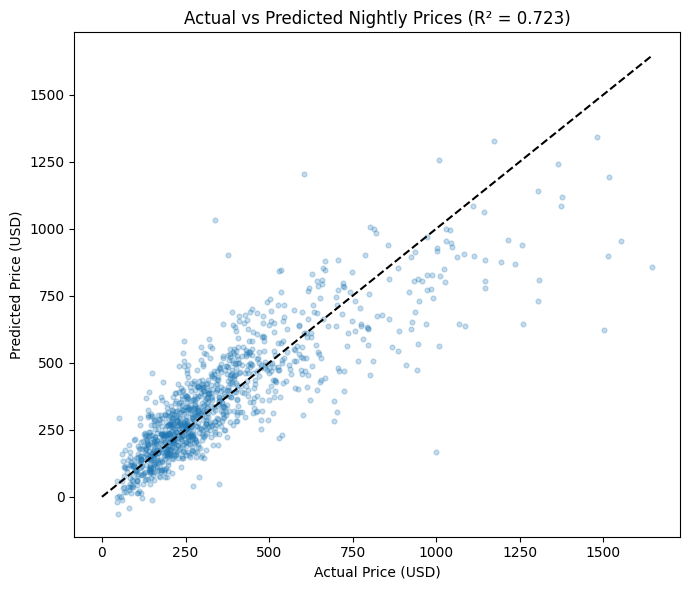

In [47]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_tec, alpha=0.25, s=12)
limit = max(y_test.max(), y_pred_tec.max())
plt.plot([0, limit], [0, limit], '--', color='black')
plt.title(f'Actual vs Predicted Nightly Prices (R² = {r2:.3f})')
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.tight_layout()
plt.show()

### 5.9 · Distribución de los errores y error por rango de precio
El **residuo** es `precio real − predicción`; un residuo positivo significa que el modelo predijo menos de lo publicado. Los rangos de precio son los mismos del TEC.

,MAE (USD),test listings
Price range,,
Up to $100,52.18,52
$100–250,62.29,402
$250–500,85.39,437
Over $500,173.88,209


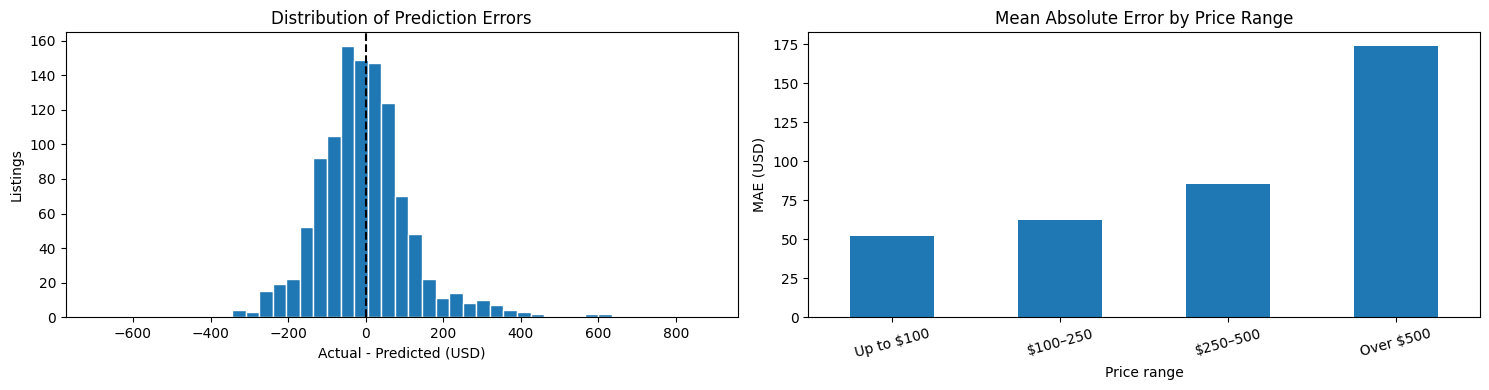

In [48]:
residuals = y_test - y_pred_tec
error_df = pd.DataFrame({'Actual': y_test, 'Error': abs(residuals)})
error_df['Price range'] = pd.cut(error_df['Actual'], bins=[0, 100, 250, 500, np.inf],
                                 labels=['Up to $100', '$100–250', '$250–500', 'Over $500'])
error_by_range = error_df.groupby('Price range', observed=False)['Error'].agg(['mean', 'count'])
error_by_range.columns = ['MAE (USD)', 'test listings']
display(error_by_range.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(residuals, bins=45, edgecolor='white')
axes[0].axvline(0, linestyle='--', color='black')
axes[0].set_title('Distribution of Prediction Errors')
axes[0].set_xlabel('Actual - Predicted (USD)'); axes[0].set_ylabel('Listings')
error_by_range['MAE (USD)'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Mean Absolute Error by Price Range'); axes[1].set_ylabel('MAE (USD)')
axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

## 6 · Comparación de modelos lineales con una misma semilla
Ridge y Lasso, con precio y con log(precio), sobre la **misma división** de la sección 5.2 (`SEED = 42`): `alpha` por validación cruzada de 3 partes sobre entrenamiento + validación, evaluación en prueba.

| Modelo | Hiperparámetros probados |
|---|---|
| **Ridge** (como el TEC, sin estandarizar) | `alpha` ∈ {0,1; 1; 10; 100} |
| **Lasso** (variables estandarizadas, porque elimina variables según el tamaño de sus coeficientes) | sin log: `alpha` ∈ {0,01; 0,1; 1; 10}; con log: `alpha` ∈ {0,00001; 0,0001; 0,001; 0,01} |

**Métricas en prueba:** R² en dólares, R² ajustado (con las variables que el modelo realmente usa), R² en escala log, MAE, error mediano, error porcentual medio y predicciones negativas.

In [49]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

cv_seed = KFold(n_splits=3, shuffle=True, random_state=SEED)

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan

def linear_pipeline(kind, alpha, numeric, categorical):
    if kind == 'Ridge':        # igual que el TEC: sin estandarizar
        prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                 remainder='passthrough')
        reg = Ridge(alpha=alpha)
    else:                      # Lasso: variables estandarizadas
        prep = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
                                  ('numeric', StandardScaler(), numeric)])
        reg = Lasso(alpha=alpha, max_iter=50_000)
    return Pipeline([('prepare', prep), ('model', reg)])

GRIDS = {('Ridge', False): [0.1, 1, 10, 100], ('Ridge', True): [0.1, 1, 10, 100],
         ('Lasso', False): [0.01, 0.1, 1, 10], ('Lasso', True): [1e-5, 1e-4, 1e-3, 1e-2]}

numeric = [c for c in BASE_FEATURES if c not in CATEGORICAL]
results = []
for use_log in [False, True]:
    y_target = np.log(y_train) if use_log else y_train
    back = np.exp if use_log else (lambda v: v)
    for kind in ['Ridge', 'Lasso']:
        scores = {a: cross_val_score(linear_pipeline(kind, a, numeric, CATEGORICAL), X_train, y_target,
                                     cv=cv_seed, scoring='r2').mean() for a in GRIDS[(kind, use_log)]}
        best = max(scores, key=scores.get)
        model = linear_pipeline(kind, best, numeric, CATEGORICAL).fit(X_train, y_target)
        pred = back(model.predict(X_test))
        n_used = int((np.abs(model.named_steps['model'].coef_) > 1e-10).sum())
        r2 = r2_score(y_test, pred)
        results.append({
            'modelo': kind, 'objetivo': 'log(precio)' if use_log else 'precio', 'alpha': best, 'variables usadas': n_used,
            'R² USD': r2, 'R² ajustado': adjusted_r2(r2, len(y_test), n_used),
            'R² log': r2_score(np.log(y_test), np.log(np.clip(pred, 1, None))),
            'MAE ($)': mean_absolute_error(y_test, pred), 'error mediano ($)': np.median(np.abs(y_test - pred)),
            'error % medio': np.mean(np.abs(pred - y_test) / y_test) * 100, 'negativas': int((pred < 0).sum()),
        })
model_comparison = pd.DataFrame(results)
print(f'Prueba: {len(y_test):,} anuncios')
model_comparison.round(3)

Prueba: 1,100 anuncios


,modelo,objetivo,alpha,variables usadas,R² USD,R² ajustado,R² log,MAE ($),error mediano ($),error % medio,negativas
0,Ridge,precio,1.00,266,0.723,0.634,0.297,92.189,65.862,30.680,7
1,Lasso,precio,0.01,248,0.721,0.640,0.315,92.259,65.387,30.683,7
2,Ridge,log(precio),1.00,266,0.707,0.613,0.782,83.593,49.463,23.709,0
3,Lasso,log(precio),0.00,213,0.708,0.638,0.783,83.282,50.132,23.642,0


## 7 · Modelos finales de regresión
| | Modelo | Qué se busca |
|---|---|---|
| **A** | **Ridge** (el modelo del equipo del TEC) | La mejor versión posible de Ridge con nuestros datos |
| **B** | **Red neuronal** (modelo propuesto) | La mejor regresión con un modelo no lineal |

**Cómo se elige "la mejor" versión, sin mirar la prueba:** Ridge, por validación cruzada de 3 partes sobre entrenamiento + validación (MAE en dólares); la red neuronal, por el MAE en dólares en el conjunto de **validación**. Los dos se evalúan **una sola vez** en la prueba.

### 7.1 · Entrenamiento y prueba

In [50]:
train_all = X_train.copy()
train_all['price_num'] = y_train
test_all = X_test.copy()
test_all['price_num'] = y_test
print(f'Entrenamiento + validación: {len(train_all):,} anuncios | Prueba: {len(test_all):,} anuncios | {len(BASE_FEATURES)} variables')

Entrenamiento + validación: 6,227 anuncios | Prueba: 1,100 anuncios | 37 variables


### 7.2 · Modelo A: la mejor versión de Ridge (modelo del TEC)
Se comparan 2 configuraciones de Ridge (siempre con `OneHotEncoder`, sin estandarizar, igual que el TEC): objetivo **precio en USD** (como el TEC) y objetivo **log(precio)**. En cada una, `alpha` ∈ {0,1; 1; 10; 100} se elige por validación cruzada (como el TEC).

In [51]:
from sklearn.model_selection import cross_val_predict

def ridge_fit(X, y, categorical):
    # alpha por validación cruzada de 3 partes (metodología del TEC)
    scores = {a: cross_val_score(tec_pipeline(categorical, a), X, y, cv=cv_seed, scoring='r2').mean()
              for a in [0.1, 1, 10, 100]}
    best = max(scores, key=scores.get)
    return tec_pipeline(categorical, best).fit(X, y), best

ridge_candidates = {}
for use_log in [False, True]:
    back = np.exp if use_log else (lambda v: v)
    y_target = np.log(train_all['price_num']) if use_log else train_all['price_num']
    model, alpha = ridge_fit(train_all[BASE_FEATURES], y_target, CATEGORICAL)
    oof = pd.Series(back(cross_val_predict(tec_pipeline(CATEGORICAL, alpha), train_all[BASE_FEATURES], y_target, cv=cv_seed)),
                    index=train_all.index)
    pred = pd.Series(back(model.predict(test_all[BASE_FEATURES])), index=test_all.index)
    label = 'log' if use_log else 'precio'
    ridge_candidates[label] = {'model': model, 'oof': oof, 'pred': pred, 'alpha': alpha,
                               'CV MAE ($)': mean_absolute_error(train_all['price_num'], oof)}

ridge_cv = pd.DataFrame({k: {'alpha': v['alpha'], 'CV MAE ($)': v['CV MAE ($)']} for k, v in ridge_candidates.items()}).T
ridge_cv['CV MAE ($)'] = ridge_cv['CV MAE ($)'].astype(float).round(2)
BEST_RIDGE = ridge_cv['CV MAE ($)'].idxmin()
display(ridge_cv.sort_values('CV MAE ($)'))
print(f'Modelo A elegido (menor MAE en validación cruzada): Ridge · {BEST_RIDGE}')

,alpha,CV MAE ($)
log,1.0,83.91
precio,1.0,93.66


Modelo A elegido (menor MAE en validación cruzada): Ridge · log


### 7.3 · Modelo B: red neuronal (modelo propuesto)
**Qué es.** Un perceptrón multicapa: capas de neuronas que combinan las variables con pesos y una activación no lineal (ReLU). Puede captar relaciones no lineales e interacciones (por ejemplo, una habitación extra no vale lo mismo en Malibú que en Lancaster) que una regresión lineal no ve.

**Diseño:**
- **Entradas:** variables numéricas estandarizadas y categóricas con one-hot.
- **Objetivo:** log(precio), estandarizado; las predicciones se devuelven a dólares con `exp`. Así el error queda en términos porcentuales (sección 4.4) y no hay precios negativos.
- **Capas ocultas:** densas con ReLU y *dropout* (apaga al azar una fracción de neuronas en cada paso para no sobreajustar); salida lineal; optimizador Adam; pérdida = error cuadrático medio (MSE).
- **División:** 70 % entrenamiento, 15 % validación (para elegir hiperparámetros), 15 % prueba (solo al final).

**Búsqueda de hiperparámetros en dos etapas** (criterio: MAE en dólares en validación):

| Etapa | Qué se prueba | Fijo |
|---|---|---|
| 1 · Arquitectura | **2, 4, 8, 16, 32 y 64 neuronas** por capa oculta × **1 y 2 capas ocultas** | tasa de aprendizaje 0,001 · *dropout* 0,1 · lote 64 |
| 2 · Entrenamiento | Tasa de aprendizaje {0,0005; 0,001; 0,005} × *dropout* {0; 0,1; 0,3} × tamaño de lote {32; 128} | la mejor arquitectura de la etapa 1 |

En las dos etapas el **número de épocas** se prueba en {25, 50, 100, 150}: cada red se entrena 150 épocas y se mide el MAE de validación al terminar las épocas 25, 50, 100 y 150.

> Requiere TensorFlow (`pip install tensorflow`). La búsqueda completa tarda unos 15–25 minutos.

In [52]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')      # oculta los mensajes informativos de TensorFlow
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

nn_prep = ColumnTransformer([('numericas', StandardScaler(), numeric),
                             ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL)])
Z_fit = nn_prep.fit_transform(X_fit).astype('float32')
Z_val = nn_prep.transform(X_val).astype('float32')
Z_test = nn_prep.transform(X_test).astype('float32')

LOG_MEAN, LOG_STD = np.log(y_fit).mean(), np.log(y_fit).std()
to_target = lambda v: ((np.log(np.asarray(v)) - LOG_MEAN) / LOG_STD).astype('float32')
to_usd = lambda t: np.exp(np.asarray(t).ravel() * LOG_STD + LOG_MEAN)
t_fit, t_val = to_target(y_fit), to_target(y_val)

EPOCH_CHECKPOINTS = [25, 50, 100, 150]

def build_network(neurons, layers, learning_rate, dropout):
    tf.keras.utils.set_random_seed(SEED)
    net = tf.keras.Sequential([tf.keras.Input(shape=(Z_fit.shape[1],))])
    for _ in range(layers):
        net.add(tf.keras.layers.Dense(neurons, activation='relu'))
        if dropout > 0:
            net.add(tf.keras.layers.Dropout(dropout))
    net.add(tf.keras.layers.Dense(1))
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mse')
    return net

class ValidationMAE(tf.keras.callbacks.Callback):
    # Guarda el MAE de validación en dólares al terminar las épocas de EPOCH_CHECKPOINTS
    def __init__(self):
        super().__init__()
        self.mae = {}
    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 in EPOCH_CHECKPOINTS:
            self.mae[epoch + 1] = mean_absolute_error(y_val, to_usd(self.model.predict(Z_val, verbose=0)))

def run_config(neurons, layers, learning_rate, dropout, batch_size, epochs=max(EPOCH_CHECKPOINTS)):
    net = build_network(neurons, layers, learning_rate, dropout)
    tracker = ValidationMAE()
    history = net.fit(Z_fit, t_fit, validation_data=(Z_val, t_val), epochs=epochs, batch_size=batch_size,
                      verbose=0, callbacks=[tracker])
    return net, history, tracker.mae

print(f'Entradas de la red: {Z_fit.shape[1]} columnas | entrenamiento: {len(Z_fit):,} | validación: {len(Z_val):,} | prueba: {len(Z_test):,}')

Entradas de la red: 265 columnas | entrenamiento: 5,128 | validación: 1,099 | prueba: 1,100


**Etapa 1 · Arquitectura:** número de neuronas por capa oculta y número de capas ocultas.

Etapa 1: 12 redes en 6.8 min
Mejor arquitectura: 1 capa(s) oculta(s) de 4 neuronas (MAE de validación = $79.08 con 100 épocas)


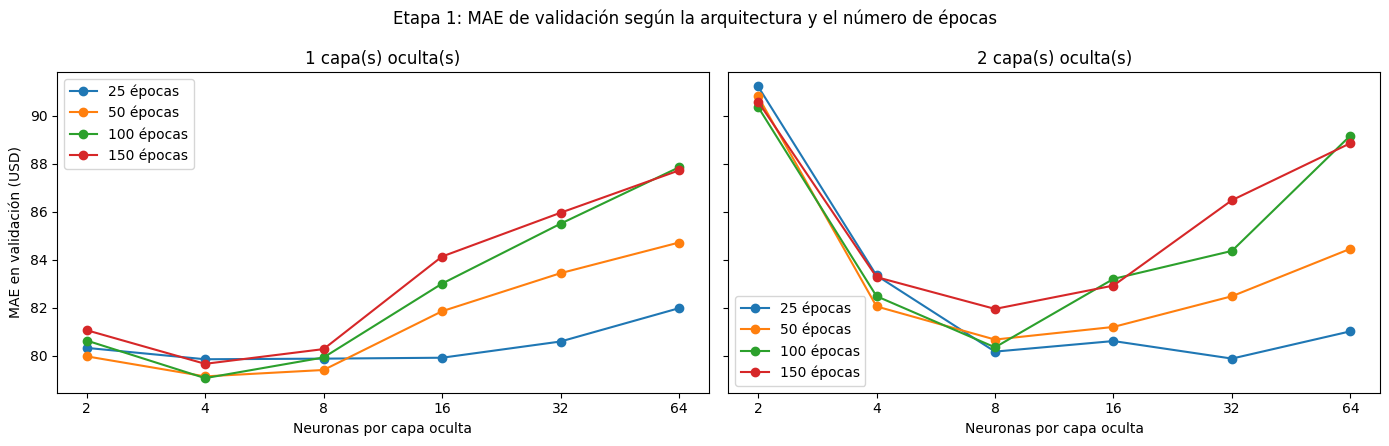

In [53]:
import time
search_rows = []
start = time.time()
for layers in [1, 2]:
    for neurons in [2, 4, 8, 16, 32, 64]:
        _, _, mae = run_config(neurons, layers, learning_rate=0.001, dropout=0.1, batch_size=64)
        for epochs, value in mae.items():
            search_rows.append({'etapa': 1, 'capas ocultas': layers, 'neuronas': neurons, 'tasa de aprendizaje': 0.001,
                                'dropout': 0.1, 'lote': 64, 'épocas': epochs, 'MAE validación ($)': value})
stage1 = pd.DataFrame(search_rows)
best1 = stage1.loc[stage1['MAE validación ($)'].idxmin()]
BEST_LAYERS, BEST_NEURONS = int(best1['capas ocultas']), int(best1['neuronas'])
print(f'Etapa 1: {len(stage1) // len(EPOCH_CHECKPOINTS)} redes en {(time.time() - start) / 60:.1f} min')
print(f'Mejor arquitectura: {BEST_LAYERS} capa(s) oculta(s) de {BEST_NEURONS} neuronas '
      f"(MAE de validación = ${best1['MAE validación ($)']:.2f} con {int(best1['épocas'])} épocas)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, layers in zip(axes, [1, 2]):
    t = stage1[stage1['capas ocultas'] == layers].pivot(index='neuronas', columns='épocas', values='MAE validación ($)')
    for epochs in t.columns:
        ax.plot(t.index, t[epochs], marker='o', label=f'{epochs} épocas')
    ax.set_xscale('log', base=2); ax.set_xticks(t.index, t.index)
    ax.set_title(f'{layers} capa(s) oculta(s)')
    ax.set_xlabel('Neuronas por capa oculta')
    ax.legend()
axes[0].set_ylabel('MAE en validación (USD)')
fig.suptitle('Etapa 1: MAE de validación según la arquitectura y el número de épocas')
plt.tight_layout()
plt.show()

**Etapa 2 · Entrenamiento:** tasa de aprendizaje, *dropout* y tamaño de lote con la mejor arquitectura.

Etapa 2: 18 redes en 10.0 min


,etapa,capas ocultas,neuronas,tasa de aprendizaje,dropout,lote,épocas,MAE validación ($)
0,2,1,4,0.0010,0.1,32,25,79.0338
1,1,1,4,0.0010,0.1,64,100,79.0758
2,1,1,4,0.0010,0.1,64,50,79.1484
3,2,1,4,0.0010,0.1,32,50,79.2392
4,2,1,4,0.0005,0.1,128,150,79.2490
5,2,1,4,0.0005,0.1,32,50,79.3687
6,2,1,4,0.0005,0.1,32,100,79.3846
7,1,1,8,0.0010,0.1,64,50,79.4157
8,2,1,4,0.0050,0.1,32,25,79.5360
9,2,1,4,0.0010,0.1,32,150,79.6179


Red elegida: 1 capa(s) oculta(s) de 4 neuronas · tasa de aprendizaje 0.001 · dropout 0.1 · lote 32 · 25 épocas · MAE de validación $79.03


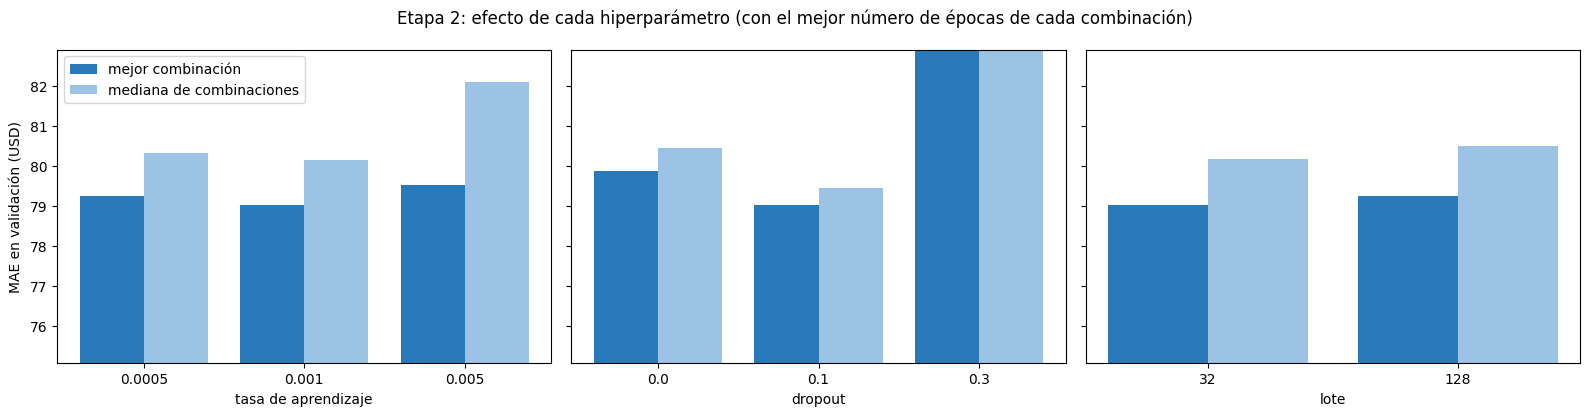

In [54]:
start = time.time()
stage2_rows = []
for learning_rate in [0.0005, 0.001, 0.005]:
    for dropout in [0.0, 0.1, 0.3]:
        for batch_size in [32, 128]:
            _, _, mae = run_config(BEST_NEURONS, BEST_LAYERS, learning_rate, dropout, batch_size)
            for epochs, value in mae.items():
                stage2_rows.append({'etapa': 2, 'capas ocultas': BEST_LAYERS, 'neuronas': BEST_NEURONS,
                                    'tasa de aprendizaje': learning_rate, 'dropout': dropout, 'lote': batch_size,
                                    'épocas': epochs, 'MAE validación ($)': value})
stage2 = pd.DataFrame(stage2_rows)
nn_search = pd.concat([stage1, stage2], ignore_index=True)
print(f'Etapa 2: {len(stage2) // len(EPOCH_CHECKPOINTS)} redes en {(time.time() - start) / 60:.1f} min')

BEST_NN = nn_search.loc[nn_search['MAE validación ($)'].idxmin()].to_dict()
BEST_NN = {k: (int(v) if k in ('capas ocultas', 'neuronas', 'lote', 'épocas', 'etapa') else v) for k, v in BEST_NN.items()}
display(nn_search.sort_values('MAE validación ($)').head(10).round(4).reset_index(drop=True))
print(f"Red elegida: {BEST_NN['capas ocultas']} capa(s) oculta(s) de {BEST_NN['neuronas']} neuronas · "
      f"tasa de aprendizaje {BEST_NN['tasa de aprendizaje']} · dropout {BEST_NN['dropout']} · lote {BEST_NN['lote']} · "
      f"{BEST_NN['épocas']} épocas · MAE de validación ${BEST_NN['MAE validación ($)']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
best_epochs_stage2 = stage2.loc[stage2.groupby(['tasa de aprendizaje', 'dropout', 'lote'])['MAE validación ($)'].idxmin()]
for ax, param in zip(axes, ['tasa de aprendizaje', 'dropout', 'lote']):
    t = best_epochs_stage2.groupby(param)['MAE validación ($)'].agg(['min', 'median'])
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['min'], 0.4, label='mejor combinación', color='#2a7ab9')
    ax.bar(x + 0.2, t['median'], 0.4, label='mediana de combinaciones', color='#9cc3e4')
    ax.set_xticks(x, t.index.astype(str))
    ax.set_xlabel(param)
    ax.set_ylim(t['min'].min() * 0.95, t['median'].max() * 1.03)
axes[0].set_ylabel('MAE en validación (USD)')
axes[0].legend()
fig.suptitle('Etapa 2: efecto de cada hiperparámetro (con el mejor número de épocas de cada combinación)')
plt.tight_layout()
plt.show()

**Red final y curva de pérdida.** Se entrena la red elegida con exactamente sus hiperparámetros (incluido el número de épocas). La curva muestra la pérdida (MSE del log-precio estandarizado) en entrenamiento y validación época por época: si la de validación sube mientras la de entrenamiento baja, la red está sobreajustando.

Parámetros entrenables de la red: 1,069
MAE de validación de la red final: $79.03


Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_66 (Dense)                  │ (None, 4)                │         1,064 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_30 (Dropout)              │ (None, 4)                │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_67 (Dense)                  │ (None, 1)                │             5 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 3,209 (12.54 KB)

 Trainable params: 1,069 (4.18 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,140 (8.36 KB)

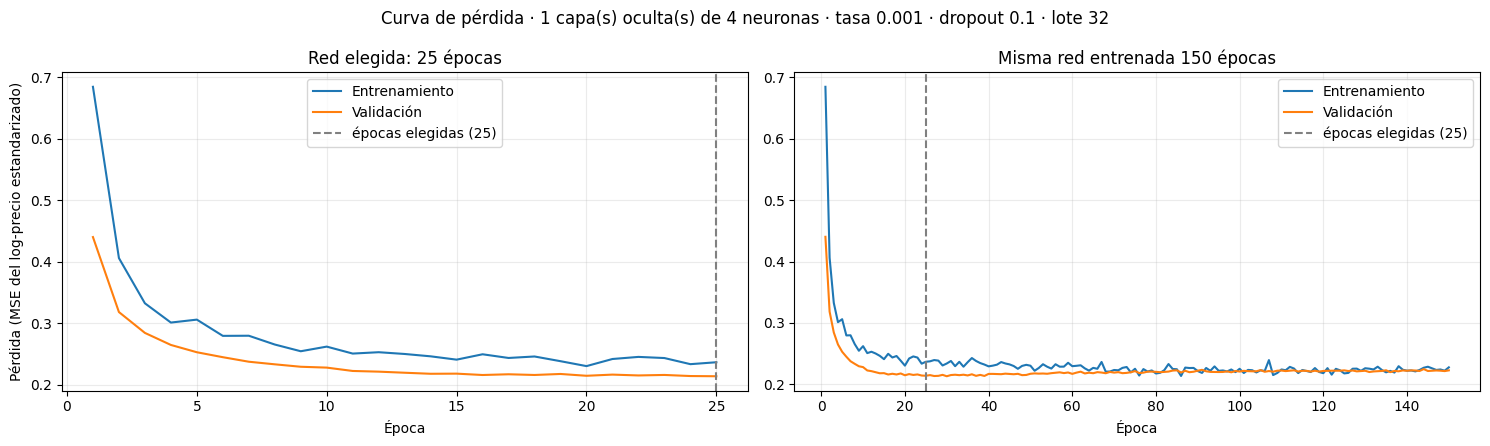

In [55]:
final_nn, nn_history, _ = run_config(BEST_NN['neuronas'], BEST_NN['capas ocultas'], BEST_NN['tasa de aprendizaje'],
                                     BEST_NN['dropout'], BEST_NN['lote'], epochs=BEST_NN['épocas'])
nn_pred = pd.Series(to_usd(final_nn.predict(Z_test, verbose=0)), index=test_all.index)
nn_val_pred = to_usd(final_nn.predict(Z_val, verbose=0))
print(f'Parámetros entrenables de la red: {final_nn.count_params():,}')
print(f'MAE de validación de la red final: ${mean_absolute_error(y_val, nn_val_pred):.2f}')
final_nn.summary(line_length=80)

# La misma configuración entrenada hasta 150 épocas, para ver qué pasa si se entrena más tiempo
_, long_history, _ = run_config(BEST_NN['neuronas'], BEST_NN['capas ocultas'], BEST_NN['tasa de aprendizaje'],
                                BEST_NN['dropout'], BEST_NN['lote'], epochs=max(EPOCH_CHECKPOINTS))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, hist, title in [(axes[0], nn_history, f"Red elegida: {BEST_NN['épocas']} épocas"),
                        (axes[1], long_history, f'Misma red entrenada {max(EPOCH_CHECKPOINTS)} épocas')]:
    epochs_axis = np.arange(1, len(hist.history['loss']) + 1)
    ax.plot(epochs_axis, hist.history['loss'], label='Entrenamiento')
    ax.plot(epochs_axis, hist.history['val_loss'], label='Validación')
    ax.axvline(BEST_NN['épocas'], linestyle='--', color='gray', label=f"épocas elegidas ({BEST_NN['épocas']})")
    ax.set_xlabel('Época')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Pérdida (MSE del log-precio estandarizado)')
fig.suptitle(f"Curva de pérdida · {BEST_NN['capas ocultas']} capa(s) oculta(s) de {BEST_NN['neuronas']} neuronas · "
             f"tasa {BEST_NN['tasa de aprendizaje']} · dropout {BEST_NN['dropout']} · lote {BEST_NN['lote']}")
plt.tight_layout()
plt.show()

**Métricas de la red en prueba:** se comparan los precios estimados con los reales de los anuncios de prueba.

,R²,R² ajustado,R² log,MAE ($),RMSE ($),error mediano ($),MAPE (%),negativas
Validación,0.721,0.632,0.785,79.034,132.110,46.953,23.007,0.0
Prueba,0.742,0.661,0.786,81.007,127.972,51.435,23.796,0.0


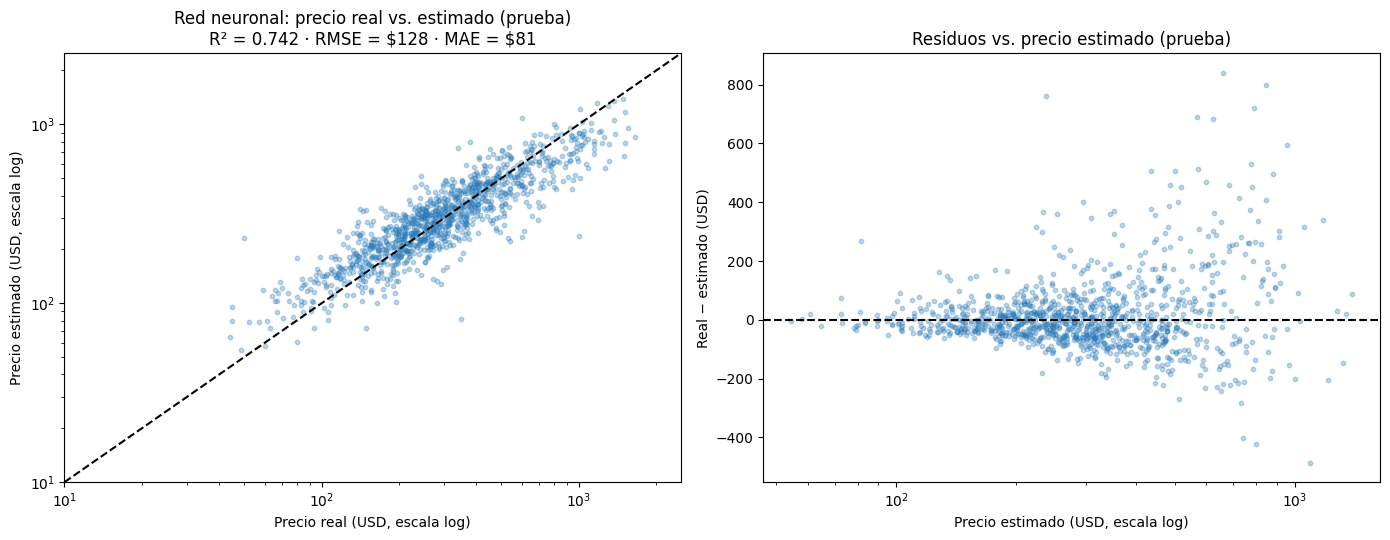

In [56]:
def final_metrics(y, p):
    return {'R²': r2_score(y, p), 'R² log': r2_score(np.log(y), np.log(np.clip(p, 1, None))),
            'MAE ($)': mean_absolute_error(y, p), 'RMSE ($)': np.sqrt(mean_squared_error(y, p)),
            'error mediano ($)': np.median(np.abs(y - p)), 'MAPE (%)': np.mean(np.abs(p - y) / y) * 100,
            'negativas': int((p < 0).sum())}

nn_metrics = pd.DataFrame({'Validación': final_metrics(y_val, nn_val_pred),
                           'Prueba': final_metrics(y_test, nn_pred)}).T
nn_metrics.insert(1, 'R² ajustado', [adjusted_r2(nn_metrics.loc[s, 'R²'], n, Z_fit.shape[1])
                                    for s, n in [('Validación', len(y_val)), ('Prueba', len(y_test))]])
display(nn_metrics.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(y_test, nn_pred, alpha=0.3, s=10, color='#2a7ab9')
axes[0].plot([10, 2500], [10, 2500], '--', color='black')
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xlim(10, 2500); axes[0].set_ylim(10, 2500)
m = nn_metrics.loc['Prueba']
axes[0].set_title(f"Red neuronal: precio real vs. estimado (prueba)\nR² = {m['R²']:.3f} · RMSE = \\${m['RMSE ($)']:.0f} · MAE = \\${m['MAE ($)']:.0f}")
axes[0].set_xlabel('Precio real (USD, escala log)'); axes[0].set_ylabel('Precio estimado (USD, escala log)')
resid_nn = y_test - nn_pred
axes[1].scatter(nn_pred, resid_nn, alpha=0.3, s=10, color='#2a7ab9')
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set_xscale('log')
axes[1].set_title('Residuos vs. precio estimado (prueba)')
axes[1].set_xlabel('Precio estimado (USD, escala log)'); axes[1].set_ylabel('Real − estimado (USD)')
plt.tight_layout()
plt.show()

### 7.4 · Comparación final en prueba
Se comparan, sobre los mismos anuncios de prueba:
- **Referencia:** Ridge del TEC tal cual (sección 5: precio sin transformar, `alpha` ∈ {1, 10, 100}).
- **Modelo A:** la mejor versión de Ridge (7.2).
- **Modelo B:** la red neuronal (7.3).

En el R² ajustado, `p` es el número de columnas de entrada del modelo después del one-hot.

,R²,R² ajustado,p (columnas),R² log,MAE ($),RMSE ($),error mediano ($),MAPE (%),negativas
Referencia: Ridge del TEC tal cual,0.723,0.634,266,0.297,92.189,132.809,65.862,30.680,7.0
Modelo A: Ridge · log,0.707,0.613,266,0.782,83.593,136.589,49.463,23.709,0.0
Modelo B: Red neuronal · log(precio),0.742,0.661,265,0.786,81.007,127.972,51.435,23.796,0.0


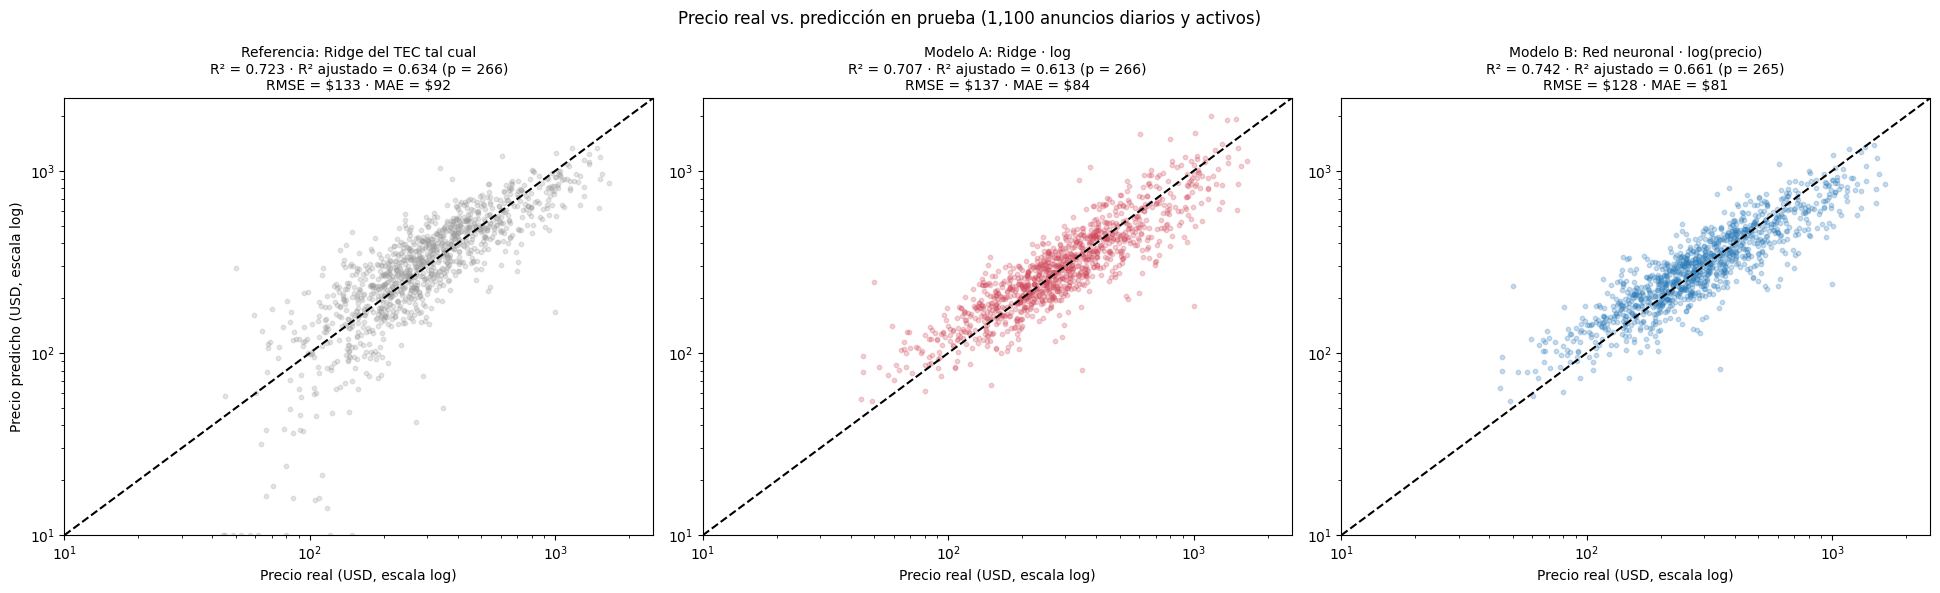

In [57]:
final_models = {'Referencia: Ridge del TEC tal cual': pd.Series(y_pred_tec, index=test_all.index),
                f'Modelo A: Ridge · {BEST_RIDGE}': ridge_candidates[BEST_RIDGE]['pred'],
                'Modelo B: Red neuronal · log(precio)': nn_pred}

ridge_cols = tec_model.named_steps['prepare'].transform(X_test.head(1)).shape[1]
P_COLUMNS = {name: ridge_cols for name in final_models}
P_COLUMNS['Modelo B: Red neuronal · log(precio)'] = Z_fit.shape[1]

final_comparison = pd.DataFrame({name: final_metrics(test_all['price_num'], pred) for name, pred in final_models.items()}).T
final_comparison.insert(1, 'R² ajustado', [adjusted_r2(final_comparison.loc[n, 'R²'], len(test_all), P_COLUMNS[n])
                                          for n in final_comparison.index])
final_comparison.insert(2, 'p (columnas)', [P_COLUMNS[n] for n in final_comparison.index])
display(final_comparison.round(3))

fig, axes = plt.subplots(1, len(final_models), figsize=(6.5 * len(final_models), 6))
colors = ['#999999', '#d1495b', '#2a7ab9']
y_true = test_all['price_num']
for ax, (model_name, pred), color in zip(np.atleast_1d(axes), final_models.items(), colors):
    m = final_comparison.loc[model_name]
    ax.scatter(y_true, np.clip(pred, 10, None), alpha=0.25, s=10, color=color)
    ax.plot([10, 2500], [10, 2500], '--', color='black')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
    ax.set_title(f"{model_name}\nR² = {m['R²']:.3f} · R² ajustado = {m['R² ajustado']:.3f} (p = {P_COLUMNS[model_name]})\n"
                 f"RMSE = \\${m['RMSE ($)']:.0f} · MAE = \\${m['MAE ($)']:.0f}", fontsize=10)
    ax.set_xlabel('Precio real (USD, escala log)')
np.atleast_1d(axes)[0].set_ylabel('Precio predicho (USD, escala log)')
fig.suptitle(f'Precio real vs. predicción en prueba ({len(test_all):,} anuncios diarios y activos)')
plt.tight_layout()
plt.show()

## 8 · Resultados finales: Modelo TEC vs. Modelo Andes
Los dos modelos finales de la sección 7, evaluados sobre los **mismos anuncios de prueba** (`SEED = 42`):

| Nombre | Modelo | Configuración |
|---|---|---|
| **Modelo TEC** | Regresión lineal **Ridge** (el modelo del equipo del TEC, en su mejor versión) | Objetivo y `alpha` elegidos por validación cruzada |
| **Modelo Andes** | **Red neuronal** (perceptrón multicapa) | Objetivo log(precio) · arquitectura, tasa de aprendizaje, *dropout*, lote y épocas elegidos en validación |

In [58]:
FINAL = {'Modelo TEC': ridge_candidates[BEST_RIDGE]['pred'], 'Modelo Andes': nn_pred}
FINAL_COLORS = {'Modelo TEC': '#d1495b', 'Modelo Andes': '#2a7ab9'}
FINAL_P = {'Modelo TEC': ridge_cols, 'Modelo Andes': Z_fit.shape[1]}

final_results = pd.DataFrame({name: final_metrics(y_true, pred) for name, pred in FINAL.items()}).T
final_results.insert(1, 'R² ajustado', [adjusted_r2(final_results.loc[n, 'R²'], len(y_true), FINAL_P[n]) for n in final_results.index])
final_results.insert(0, 'anuncios', len(y_true))
final_results.round(3)

,anuncios,R²,R² ajustado,R² log,MAE ($),RMSE ($),error mediano ($),MAPE (%),negativas
Modelo TEC,1100,0.707,0.613,0.782,83.593,136.589,49.463,23.709,0.0
Modelo Andes,1100,0.742,0.661,0.786,81.007,127.972,51.435,23.796,0.0


### 8.1 · Precio real vs. predicción
Escala logarítmica en los dos ejes para que se vean bien los precios bajos y altos. Mientras más cerca de la diagonal, mejor.

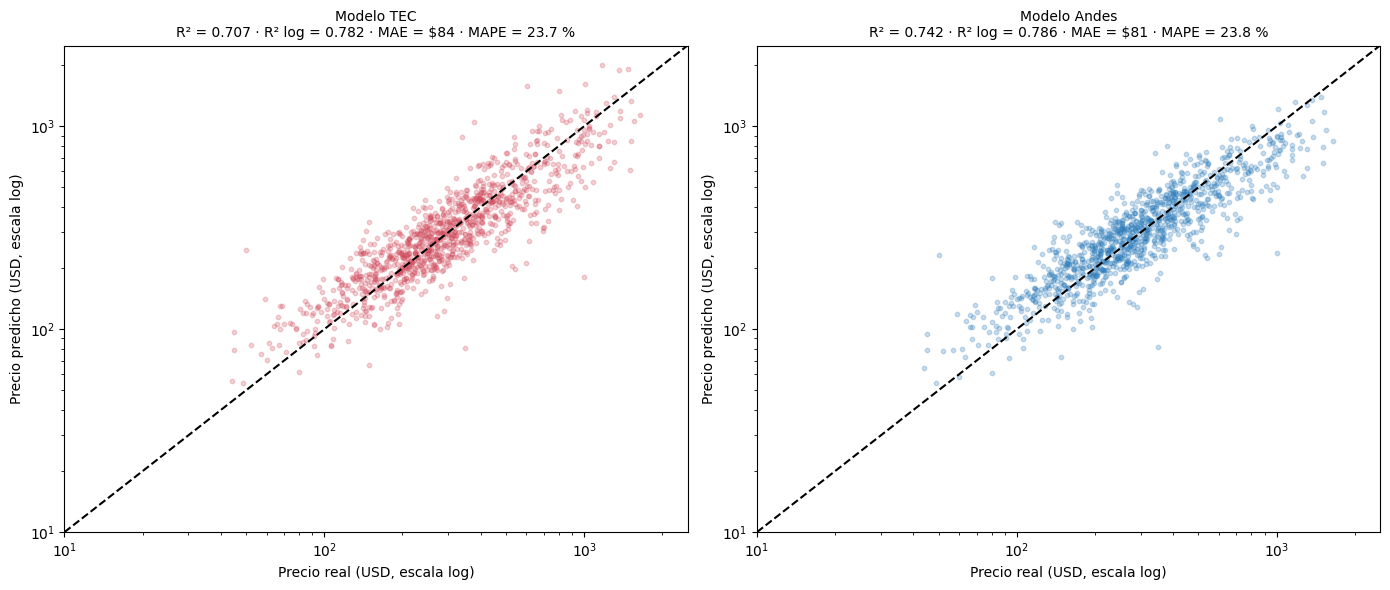

In [59]:
fig, axes = plt.subplots(1, len(FINAL), figsize=(7 * len(FINAL), 6))
for ax, (model_name, pred) in zip(np.atleast_1d(axes), FINAL.items()):
    ax.scatter(y_true, np.clip(pred, 10, None), alpha=0.25, s=10, color=FINAL_COLORS[model_name])
    ax.plot([10, 2500], [10, 2500], '--', color='black')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(10, 2500); ax.set_ylim(10, 2500)
    m = final_results.loc[model_name]
    ax.set_title(f"{model_name}\nR² = {m['R²']:.3f} · R² log = {m['R² log']:.3f} · MAE = \\${m['MAE ($)']:.0f} · MAPE = {m['MAPE (%)']:.1f} %",
                 fontsize=10)
    ax.set_xlabel('Precio real (USD, escala log)')
    ax.set_ylabel('Precio predicho (USD, escala log)')
plt.tight_layout()
plt.show()

### 8.2 · Distribución del error
Error porcentual de cada predicción: `(predicción − real) / real`. Un valor negativo significa que el modelo predijo menos que el precio publicado. Mientras más concentrado alrededor de 0, mejor.

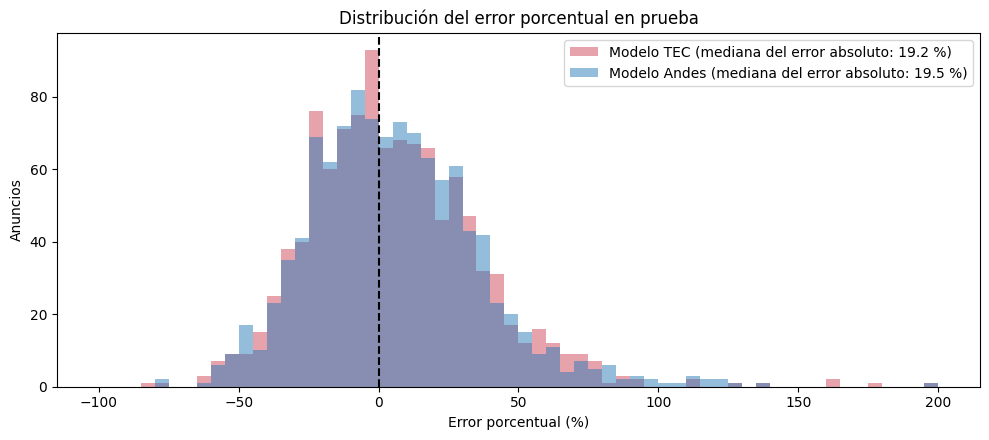

In [60]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(-100, 200, 61)
for model_name, pred in FINAL.items():
    pct_error = ((pred - y_true) / y_true * 100).clip(-100, 200)
    ax.hist(pct_error, bins=bins, alpha=0.5, color=FINAL_COLORS[model_name],
            label=f'{model_name} (mediana del error absoluto: {np.median(np.abs(pct_error)):.1f} %)')
ax.axvline(0, linestyle='--', color='black')
ax.set_xlabel('Error porcentual (%)')
ax.set_ylabel('Anuncios')
ax.set_title('Distribución del error porcentual en prueba')
ax.legend()
plt.tight_layout()
plt.show()

### 8.3 · Error por rango de precio

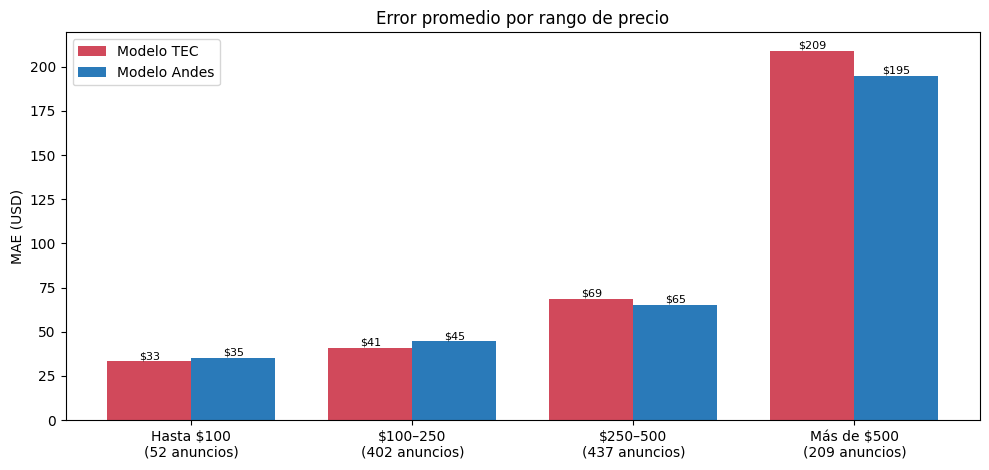

In [61]:
fig, ax = plt.subplots(figsize=(10, 4.8))
width = 0.38
price_range = pd.cut(y_true, bins=[0, 100, 250, 500, np.inf],
                     labels=['Hasta $100', '$100–250', '$250–500', 'Más de $500'])
mae_range = pd.DataFrame({m: (p - y_true).abs().groupby(price_range, observed=False).mean() for m, p in FINAL.items()})
x = np.arange(len(mae_range))
for k, model_name in enumerate(FINAL):
    bars = ax.bar(x + (k - 0.5) * width, mae_range[model_name], width, label=model_name, color=FINAL_COLORS[model_name])
    ax.bar_label(bars, fmt='$%.0f', fontsize=8)
counts = price_range.value_counts().reindex(mae_range.index)
ax.set_xticks(x, [f'{r}\n({n:,} anuncios)' for r, n in counts.items()])
ax.set_ylabel('MAE (USD)')
ax.set_title('Error promedio por rango de precio')
ax.legend()
plt.tight_layout()
plt.show()

### 8.4 · Resumen

In [62]:
summary_final = final_results[['R²', 'R² ajustado', 'R² log', 'MAE ($)', 'RMSE ($)', 'MAPE (%)', 'negativas']]
display(summary_final.round(3))
tec, andes = summary_final.loc['Modelo TEC'], summary_final.loc['Modelo Andes']
better = 'reduce' if andes['MAE ($)'] < tec['MAE ($)'] else 'aumenta'
print(f"El Modelo Andes {better} el MAE de ${tec['MAE ($)']:.0f} a ${andes['MAE ($)']:.0f} "
      f"({(andes['MAE ($)'] / tec['MAE ($)'] - 1) * 100:+.1f} %) y el error porcentual medio pasa de "
      f"{tec['MAPE (%)']:.1f} % a {andes['MAPE (%)']:.1f} %.")
print(f"R² en dólares: {tec['R²']:.3f} (TEC) vs {andes['R²']:.3f} (Andes) | "
      f"R² ajustado: {tec['R² ajustado']:.3f} (TEC) vs {andes['R² ajustado']:.3f} (Andes) | "
      f"RMSE: ${tec['RMSE ($)']:.0f} (TEC) vs ${andes['RMSE ($)']:.0f} (Andes)")

,R²,R² ajustado,R² log,MAE ($),RMSE ($),MAPE (%),negativas
Modelo TEC,0.707,0.613,0.782,83.593,136.589,23.709,0.0
Modelo Andes,0.742,0.661,0.786,81.007,127.972,23.796,0.0


El Modelo Andes reduce el MAE de $84 a $81 (-3.1 %) y el error porcentual medio pasa de 23.7 % a 23.8 %.
R² en dólares: 0.707 (TEC) vs 0.742 (Andes) | R² ajustado: 0.613 (TEC) vs 0.661 (Andes) | RMSE: $137 (TEC) vs $128 (Andes)


## 9 · Modelos de clasificación
Dos formas de decir si el precio de un anuncio es adecuado, con la misma división de la sección 5.2 (referencias calculadas con entrenamiento + validación, evaluación en prueba):

| | Modelo TEC | Modelo Andes (Daniel Babativa) |
|---|---|---|
| Referencia | Mediana de anuncios comparables de entrenamiento (vecindario, tipo, habitaciones y huéspedes) | Precio predicho por el Modelo TEC de regresión (sección 7.2) |
| Etiqueta | 3 clases: < 90 % Opportunity to Charge More · 90–110 % Competitive · > 110 % Too High | 2 clases: precio ≤ referencia (competitivo) · precio > referencia (no competitivo) |
| Clasificador | Árbol de decisión (`max_depth=2`) con `price_ratio` | Red neuronal (2 o 3 capas ocultas) con las variables del anuncio y su precio |

Al final (9.3) se revisa si las alertas se relacionan con la **ocupación** real de los anuncios, que ninguno de los dos modelos usa.

### 9.1 · Modelo TEC: mediana de comparables ±10 %
Se repite **exactamente la clasificación del equipo del TEC** (secciones 6.1, 6.2 y 8.1–8.4 de su notebook). Las medianas se calculan **solo con anuncios de entrenamiento**; si hay menos de 5 comparables se usa la mediana del vecindario y, si no existe, la mediana global de entrenamiento.

Grupos de comparables en entrenamiento: 3,525
Anuncios de prueba con ≥ 5 comparables: 21.2%


,anuncios,%
pricing_alert,,
Opportunity to Charge More,439,39.9
Competitive,197,17.9
Too High,464,42.2


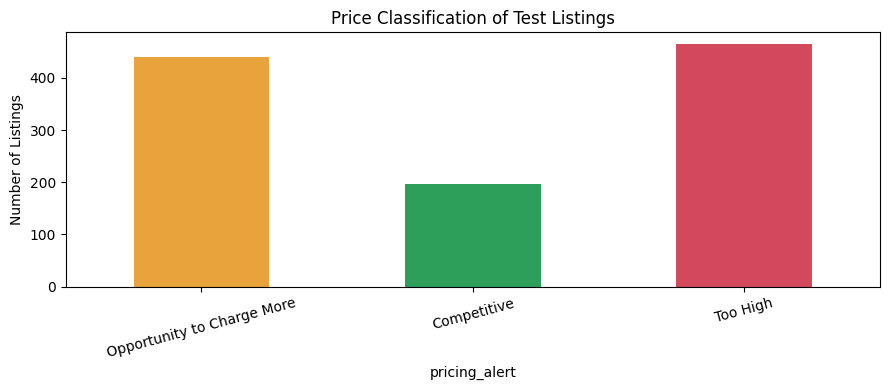

In [63]:
GROUP_COLS = ['neighbourhood_model', 'property_type_model', 'bedrooms', 'accommodates']
reference = train_all[GROUP_COLS + ['price_num']].copy()

market = reference.groupby(GROUP_COLS)['price_num'].agg(['median', 'count'])
neighborhood_medians = reference.groupby('neighbourhood_model')['price_num'].median()
overall_median = reference['price_num'].median()

def market_median_for(frame):
    joined = frame[GROUP_COLS].join(market, on=GROUP_COLS)
    fallback = frame['neighbourhood_model'].map(neighborhood_medians)
    has_comparables = joined['count'] >= 5
    return joined['median'].where(has_comparables, fallback).fillna(overall_median), has_comparables

ALERT_CLASSES = ['Opportunity to Charge More', 'Competitive', 'Too High']

def pricing_alert(ratio):
    return np.select([ratio < 0.90, ratio > 1.10], ['Opportunity to Charge More', 'Too High'], default='Competitive')

classified = test_all[['price_num'] + GROUP_COLS].copy()
classified['market_median'], classified['has_5_comparables'] = market_median_for(classified)
classified['price_ratio'] = classified['price_num'] / classified['market_median']
classified['pricing_alert'] = pricing_alert(classified['price_ratio'])
print(f'Grupos de comparables en entrenamiento: {len(market):,}')
print(f"Anuncios de prueba con ≥ 5 comparables: {classified['has_5_comparables'].mean():.1%}")

alert_counts = classified['pricing_alert'].value_counts().reindex(ALERT_CLASSES)
display(alert_counts.to_frame('anuncios').assign(**{'%': (alert_counts / len(classified) * 100).round(1)}))
alert_counts.plot(kind='bar', figsize=(9, 4), color=['#e8a33d', '#2e9e5b', '#d1495b'])
plt.title('Price Classification of Test Listings')
plt.ylabel('Number of Listings')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

|--- price_ratio <= 1.100
|   |--- price_ratio <= 0.900
|   |   |--- class: Opportunity to Charge More
|   |--- price_ratio >  0.900
|   |   |--- class: Competitive
|--- price_ratio >  1.100
|   |--- class: Too High



,Accuracy,Precision,Recall,F1-score
Diarios y activos,1.0,1.0,1.0,1.0
TEC original (su base),1.0,1.0,1.0,1.0


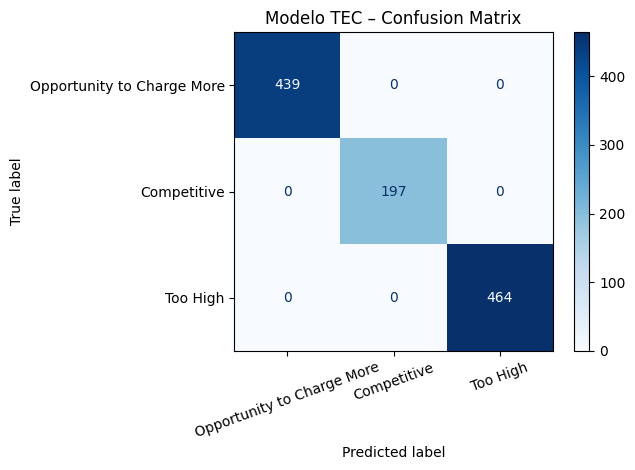

In [64]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# Etiquetas de entrenamiento con la misma regla y árbol de decisión que la aprende
train_median, _ = market_median_for(reference)
train_ratio = reference['price_num'] / train_median
train_labels = pricing_alert(train_ratio)
classification_model = DecisionTreeClassifier(max_depth=2, random_state=SEED)
classification_model.fit(pd.DataFrame({'price_ratio': train_ratio}), train_labels)
print(export_text(classification_model, feature_names=['price_ratio'], decimals=3))

class_test_y = classified['pricing_alert']
class_pred = classification_model.predict(classified[['price_ratio']])
class_results = pd.DataFrame([{
    'Accuracy': accuracy_score(class_test_y, class_pred),
    'Precision': precision_score(class_test_y, class_pred, average='weighted'),
    'Recall': recall_score(class_test_y, class_pred, average='weighted'),
    'F1-score': f1_score(class_test_y, class_pred, average='weighted'),
}], index=['Diarios y activos'])
class_results.loc['TEC original (su base)'] = [1.0, 1.0, 1.0, 1.0]
display(class_results.round(4))

ConfusionMatrixDisplay.from_predictions(class_test_y, class_pred, labels=ALERT_CLASSES, cmap='Blues', xticks_rotation=20)
plt.title('Modelo TEC – Confusion Matrix')
plt.tight_layout()
plt.show()

**Interpretación (igual que el TEC):** una accuracy cercana al 100 % significa que el árbol replica el umbral de ±10 %, porque aprende de etiquetas calculadas con esa misma regla. **No** demuestra que esos precios aumenten las reservas.

### 9.2 · Modelo Andes: red neuronal de clasificación (Daniel Babativa)
- **Referencia:** precio predicho por el Modelo TEC de regresión (predicciones fuera de muestra en entrenamiento y predicciones normales en prueba).
- **Etiqueta:** índice = precio publicado ÷ referencia; **1 = competitivo** si el índice es ≤ 1 y **0 = no competitivo** si es > 1.
- **Predictores:** las variables del modelo más el precio publicado, numéricas estandarizadas y categóricas con one-hot; pesos por clase para compensar el desbalance.
- **Arquitecturas:** 2 y 3 capas ocultas con ReLU y *dropout* de 0,2, salida sigmoide, Adam y parada temprana. Se elige la de mayor **AUC en validación** y se evalúa una sola vez en prueba.

> Requiere TensorFlow (`pip install tensorflow`).

Referencia de precio: Ridge · log
Anuncios para clasificar: 7,327
Clases en entrenamiento (0 = no competitivo, 1 = competitivo):
0    3012
1    3215
Name: count, dtype: int64
Pesos usados por clase: {0: 1.0338314653383147, 1: 0.9683125972006221}


,Accuracy,Accuracy balanceada,Precisión,Valor predictivo negativo (NPV),Recall,Error de predicciones positivas (FDR),Error de predicciones negativas (FOR),Falsos positivos (FPR),Falsos negativos (FNR),AUC,Pérdida BCE validación
3 capas: 64-32-16,0.881,0.880,0.857,0.911,0.924,0.143,0.089,0.164,0.076,0.960,0.276
2 capas: 32-16,0.896,0.895,0.879,0.916,0.925,0.121,0.084,0.136,0.075,0.960,0.266
3 capas: 32-16-8,0.892,0.892,0.878,0.909,0.919,0.122,0.091,0.136,0.081,0.958,0.275
2 capas: 64-32,0.886,0.886,0.888,0.884,0.891,0.112,0.116,0.119,0.109,0.958,0.266


Red seleccionada por AUC de validación: 3 capas: 64-32-16


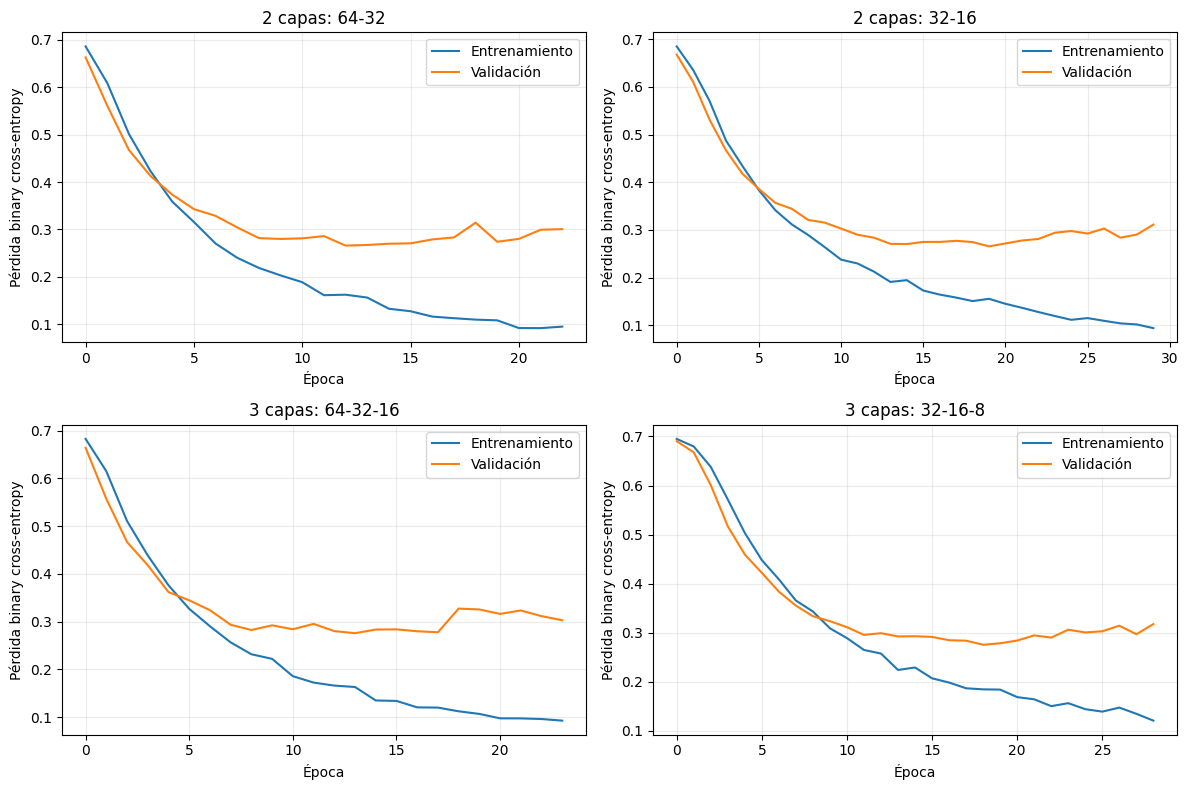

,Accuracy,Accuracy balanceada,Precisión,Valor predictivo negativo (NPV),Recall,Error de predicciones positivas (FDR),Error de predicciones negativas (FOR),Falsos positivos (FPR),Falsos negativos (FNR),AUC,Pérdida BCE prueba
Prueba: 3 capas: 64-32-16,0.896,0.895,0.878,0.92,0.932,0.122,0.08,0.143,0.068,0.967,0.251


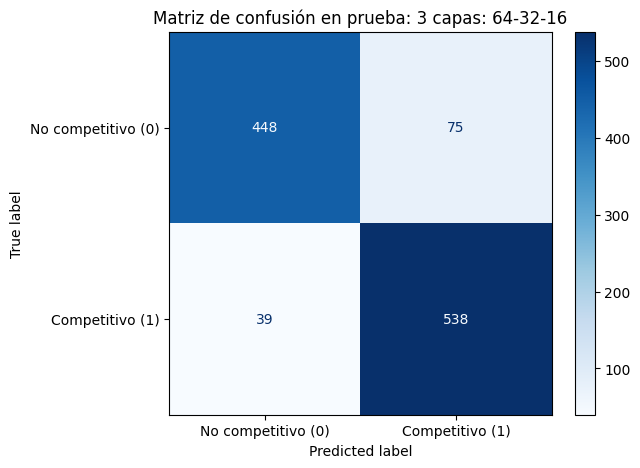

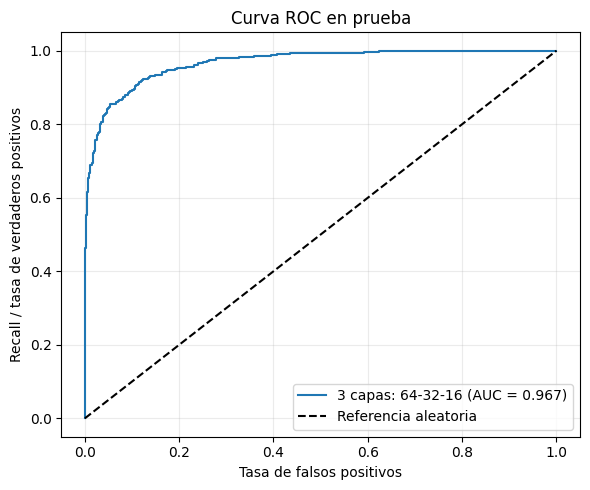

,precio_publicado_usd,precio_referencia_usd,indice_precio,etiqueta_regla,probabilidad_competitivo,clasificacion_red
3163,302.67,339.001,0.893,1,0.990,1
1562,538.67,430.901,1.250,0,0.113,0
4482,60.14,70.637,0.851,1,0.156,0
3721,633.50,628.398,1.008,0,0.896,1
3688,197.00,152.934,1.288,0,0.029,0
3997,363.50,620.212,0.586,1,1.000,1
5682,513.93,649.334,0.791,1,0.975,1
1512,219.12,396.496,0.553,1,1.000,1
1891,258.00,298.175,0.865,1,0.999,1
7222,57.00,75.204,0.758,1,0.968,1


In [65]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')      # oculta los mensajes informativos de TensorFlow
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve

# Usamos las predicciones fuera de muestra del mejor Ridge (Modelo TEC, sección 7.2) para definir
# el precio de referencia de cada anuncio.
SEMILLA_RED = int(globals().get("SEED", 42))

idx_train = train_all.index
idx_test = test_all.index

precio_train = train_all.loc[idx_train, "price_num"].to_numpy(dtype=float)
referencia_train = (
    ridge_candidates[BEST_RIDGE]["oof"].loc[idx_train].to_numpy(dtype=float)
)

precio_test = test_all.loc[idx_test, "price_num"].to_numpy(dtype=float)
referencia_test = (
    ridge_candidates[BEST_RIDGE]["pred"].loc[idx_test].to_numpy(dtype=float)
)

# Excluir únicamente filas cuyo precio o referencia no sean válidos.
valid_train = np.isfinite(precio_train) & np.isfinite(referencia_train)
valid_test = np.isfinite(precio_test) & np.isfinite(referencia_test)

idx_train = idx_train[valid_train]
idx_test = idx_test[valid_test]

precio_train = precio_train[valid_train]
referencia_train = referencia_train[valid_train]
precio_test = precio_test[valid_test]
referencia_test = referencia_test[valid_test]

# Evitar referencias cero o negativas al calcular la relación de precios.
referencia_train = np.clip(referencia_train, 10, None)
referencia_test = np.clip(referencia_test, 10, None)

# Índice = precio publicado / precio de referencia.
# Etiqueta 1: precio igual o menor a la referencia.
# Etiqueta 0: precio mayor a la referencia.
indice_train = precio_train / referencia_train
indice_test = precio_test / referencia_test

y_train_red = (indice_train <= 1.0).astype(int)
y_test_red = (indice_test <= 1.0).astype(int)

# Los predictores son las variables del modelo más el precio publicado.
X_train_red = train_all.loc[idx_train, BASE_FEATURES].copy()
X_train_red["price_num"] = precio_train

X_test_red = test_all.loc[idx_test, BASE_FEATURES].copy()
X_test_red["price_num"] = precio_test

print(f"Referencia de precio: Ridge · {BEST_RIDGE}")
print(f"Anuncios para clasificar: {len(X_train_red) + len(X_test_red):,}")
print("Clases en entrenamiento (0 = no competitivo, 1 = competitivo):")
print(pd.Series(y_train_red).value_counts().sort_index())

if len(np.unique(y_train_red)) < 2 or len(np.unique(y_test_red)) < 2:
    raise ValueError(
        "La etiqueta quedó con una sola clase en entrenamiento o prueba. "
        "Revisa la regla del índice de precio."
    )

# Separar entrenamiento y validación. El conjunto de prueba queda apartado.
indices = np.arange(len(y_train_red))
idx_fit, idx_val = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEMILLA_RED,
    stratify=y_train_red
)

X_fit = X_train_red.iloc[idx_fit].copy()
X_val = X_train_red.iloc[idx_val].copy()
y_fit = y_train_red[idx_fit]
y_val = y_train_red[idx_val]

# Preparación de variables: estandarizar numéricas y codificar categóricas.
columnas_categoricas = X_fit.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()
columnas_numericas = [
    c for c in X_fit.columns if c not in columnas_categoricas
]

try:
    codificador = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibilidad con versiones anteriores de scikit-learn.
    codificador = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

transformaciones = []

if columnas_numericas:
    transformaciones.append((
        "numericas",
        Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler())
        ]),
        columnas_numericas
    ))

if columnas_categoricas:
    transformaciones.append((
        "categoricas",
        Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", codificador)
        ]),
        columnas_categoricas
    ))

preprocesador_red = ColumnTransformer(transformaciones)

X_fit_np = preprocesador_red.fit_transform(X_fit).astype("float32")
X_val_np = preprocesador_red.transform(X_val).astype("float32")
X_test_np = preprocesador_red.transform(X_test_red).astype("float32")

# Compensar el desbalance entre las clases.
clases = np.unique(y_fit)
pesos = compute_class_weight(
    class_weight="balanced",
    classes=clases,
    y=y_fit
)
pesos_clase = {
    int(clase): float(peso)
    for clase, peso in zip(clases, pesos)
}
print("Pesos usados por clase:", pesos_clase)

# Métricas de clasificación. La clase positiva (1) es "competitivo por precio".
def calcular_metricas(y_real, probabilidades):
    predicciones = (probabilidades >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_real, predicciones, labels=[0, 1]
    ).ravel()

    def dividir_seguro(a, b):
        return a / b if b else np.nan

    sensibilidad = dividir_seguro(tp, tp + fn)
    especificidad = dividir_seguro(tn, tn + fp)

    return {
        "Accuracy": dividir_seguro(tp + tn, tp + tn + fp + fn),
        "Accuracy balanceada": (sensibilidad + especificidad) / 2,
        "Precisión": dividir_seguro(tp, tp + fp),
        "Valor predictivo negativo (NPV)": dividir_seguro(tn, tn + fn),
        "Recall": sensibilidad,
        "Error de predicciones positivas (FDR)": dividir_seguro(fp, tp + fp),
        "Error de predicciones negativas (FOR)": dividir_seguro(fn, tn + fn),
        "Falsos positivos (FPR)": dividir_seguro(fp, fp + tn),
        "Falsos negativos (FNR)": dividir_seguro(fn, fn + tp),
        "AUC": roc_auc_score(y_real, probabilidades)
    }

# Redes con dos y tres capas ocultas.
arquitecturas = {
    "2 capas: 64-32": [64, 32],
    "2 capas: 32-16": [32, 16],
    "3 capas: 64-32-16": [64, 32, 16],
    "3 capas: 32-16-8": [32, 16, 8]
}

modelos_red = {}
historiales_red = {}
resultados_validacion = {}

for nombre, neuronas in arquitecturas.items():
    tf.keras.utils.set_random_seed(SEMILLA_RED)

    capas = [tf.keras.Input(shape=(X_fit_np.shape[1],))]
    for cantidad in neuronas:
        capas.append(tf.keras.layers.Dense(cantidad, activation="relu"))
        capas.append(tf.keras.layers.Dropout(0.20))
    capas.append(tf.keras.layers.Dense(1, activation="sigmoid"))

    modelo = tf.keras.Sequential(capas)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    historial = modelo.fit(
        X_fit_np,
        y_fit,
        validation_data=(X_val_np, y_val),
        epochs=100,
        batch_size=32,
        class_weight=pesos_clase,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    prob_val = modelo.predict(X_val_np, verbose=0).ravel()
    metricas = calcular_metricas(y_val, prob_val)
    metricas["Pérdida BCE validación"] = modelo.evaluate(
        X_val_np, y_val, verbose=0
    )[0]

    modelos_red[nombre] = modelo
    historiales_red[nombre] = historial
    resultados_validacion[nombre] = metricas

# Comparar arquitecturas solo con validación y escoger por AUC.
tabla_validacion = pd.DataFrame(resultados_validacion).T
display(tabla_validacion.sort_values("AUC", ascending=False).round(3))

mejor_nombre = max(
    resultados_validacion,
    key=lambda nombre: resultados_validacion[nombre]["AUC"]
)
modelo_recomendacion = modelos_red[mejor_nombre]

print(f"Red seleccionada por AUC de validación: {mejor_nombre}")

# Curvas de pérdida para las arquitecturas evaluadas.
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for eje, (nombre, historial) in zip(ejes.ravel(), historiales_red.items()):
    eje.plot(historial.history["loss"], label="Entrenamiento")
    eje.plot(historial.history["val_loss"], label="Validación")
    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("Pérdida binary cross-entropy")
    eje.legend()
    eje.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# Evaluación final: el conjunto de prueba se usa solo para la red seleccionada.
prob_test = modelo_recomendacion.predict(X_test_np, verbose=0).ravel()
metricas_test = calcular_metricas(y_test_red, prob_test)
metricas_test["Pérdida BCE prueba"] = modelo_recomendacion.evaluate(
    X_test_np, y_test_red, verbose=0
)[0]

display(pd.DataFrame(
    [metricas_test],
    index=[f"Prueba: {mejor_nombre}"]
).round(3))

# Matriz de confusión en prueba.
pred_test = (prob_test >= 0.5).astype(int)
matriz = confusion_matrix(y_test_red, pred_test, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No competitivo (0)", "Competitivo (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusión en prueba: {mejor_nombre}")
plt.tight_layout()
plt.show()

# Curva ROC en prueba.
fpr, tpr, _ = roc_curve(y_test_red, prob_test)
auc_test = roc_auc_score(y_test_red, prob_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"{mejor_nombre} (AUC = {auc_test:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Referencia aleatoria")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Recall / tasa de verdaderos positivos")
plt.title("Curva ROC en prueba")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Ejemplos de anuncios de prueba y su resultado.
resultado_recomendacion = pd.DataFrame({
    "precio_publicado_usd": precio_test,
    "precio_referencia_usd": referencia_test,
    "indice_precio": indice_test,
    "etiqueta_regla": y_test_red,
    "probabilidad_competitivo": prob_test,
    "clasificacion_red": pred_test
}, index=idx_test)

display(resultado_recomendacion.head(10).round(3))

In [66]:
print(f'La red elegida fue {mejor_nombre}, porque obtuvo el mayor AUC en validación '
      f"({resultados_validacion[mejor_nombre]['AUC']:.3f}). En prueba: accuracy = {metricas_test['Accuracy']:.3f}, "
      f"recall = {metricas_test['Recall']:.3f}, AUC = {metricas_test['AUC']:.3f}.")

La red elegida fue 3 capas: 64-32-16, porque obtuvo el mayor AUC en validación (0.960). En prueba: accuracy = 0.896, recall = 0.932, AUC = 0.967.


### 9.3 · ¿Las alertas se relacionan con la ocupación?
En los datos no existe una etiqueta con el "precio correcto", así que las métricas de 9.1 y 9.2 solo miden qué tan bien cada clasificador copia su propia regla. Una validación externa es la **ocupación estimada** de los últimos 12 meses (`ocupacion`), que ningún modelo usó: si un anuncio está "muy caro", debería ocuparse menos.

Se compara la ocupación mediana de los anuncios de prueba según la alerta de cada modelo.

ocupación mediana (días)  \
modelo             alerta                                                    
Modelo TEC         Competitive                                       144.0   
                   Opportunity to Charge More                        132.0   
                   Too High                                          108.0   
Modelo Andes (red) Competitivo (≤ referencia)                        138.0   
                   No competitivo (> referencia)                     102.0   

                                                  ocupación promedio (días)  \
modelo             alerta                                                     
Modelo TEC         Competitive                                        143.2   
                   Opportunity to Charge More                         140.4   
                   Too High                                           116.5   
Modelo Andes (red) Competitivo (≤ referencia)                         141.7   
                   No competitivo (> referencia)                      117.1   

                                                  anuncios  
modelo             alerta                                   
Modelo TEC         Competitive                         197  
                   Opportunity to Charge More          439  
                   Too High                            464  
Modelo Andes (red) Competitivo (≤ referencia)          613  
                   No competitivo (> referencia)       487

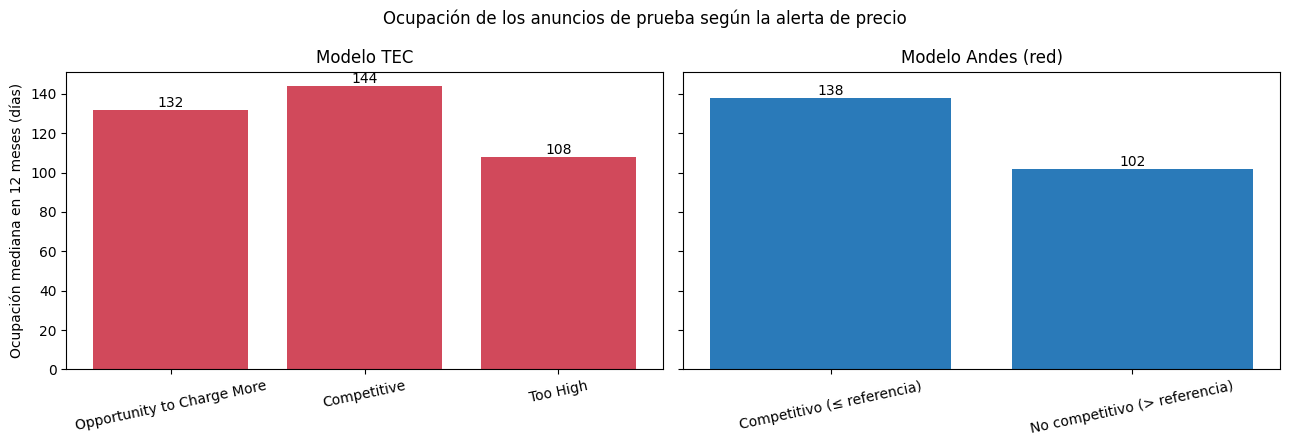

In [67]:
occupancy = df_modelo.loc[test_all.index, 'ocupacion']
occ_rows = []
for model_name, labels in [('Modelo TEC', classified['pricing_alert']),
                           ('Modelo Andes (red)', pd.Series(np.where(pred_test == 1, 'Competitivo (≤ referencia)',
                                                                     'No competitivo (> referencia)'), index=idx_test))]:
    t = occupancy.groupby(labels).agg(['median', 'mean', 'size'])
    t.columns = ['ocupación mediana (días)', 'ocupación promedio (días)', 'anuncios']
    t.index = pd.MultiIndex.from_product([[model_name], t.index], names=['modelo', 'alerta'])
    occ_rows.append(t)
occupancy_table = pd.concat(occ_rows)
display(occupancy_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (model_name, t), color in zip(axes, occupancy_table.groupby(level='modelo', sort=False), ['#d1495b', '#2a7ab9']):
    t = t.droplevel('modelo')
    if model_name == 'Modelo TEC':
        t = t.reindex(ALERT_CLASSES)
    bars = ax.bar(t.index, t['ocupación mediana (días)'], color=color)
    ax.bar_label(bars, fmt='%.0f')
    ax.set_title(model_name)
    ax.tick_params(axis='x', rotation=12)
axes[0].set_ylabel('Ocupación mediana en 12 meses (días)')
fig.suptitle('Ocupación de los anuncios de prueba según la alerta de precio')
plt.tight_layout()
plt.show()